# Setup

- Python 3.12.2; MIMIC-IV v3.1 access on BigQuery; a billing-enabled Google Cloud project.
- For local authentication: `gcloud auth application-default login`. Set `PROJECT_ID` below, then run all cells in order.
- Results: a new run folder under `models/outputs` in the working directory.

Package versions:

python
%pip install numpy==2.4.4 pandas==3.0.2 scipy==1.17.1 scikit-learn==1.8.0 xgboost==3.2.0 matplotlib==3.10.8 joblib==1.5.3 google-cloud-bigquery==3.44.0 db-dtypes==1.7.1 pyarrow==19.0.1 google-auth==2.38.0 ipython==8.12.3



In [38]:
import pandas as pd
import numpy as np
from google.cloud import bigquery
import matplotlib.pyplot as plt
from pathlib import Path
from copy import deepcopy
import csv
import hashlib
import importlib.metadata
import json
import platform
import re
import warnings
import joblib
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
    confusion_matrix, log_loss, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import DMatrix, XGBClassifier
from IPython.display import display, Image


In [39]:
#imports

PROJECT_ID = 'comp90089-507410'

client = bigquery.Client(project=PROJECT_ID)
INTERVAL = 6
MISSING = 0.5

def run_query(query):
    query_job = client.query(query)
    return query_job.to_dataframe()

# 1. Cohort construction (Methods 2.1, Table A.1)


**Cohort definition**
* Adult ICU patients with mechanical ventilation
    * Defined as first planned ICU extubation per patient with preceding invasive ventilation during the same icu stay (adapted from Zhao et al. 2021)
    * Unplanned events excluded
* First extubation
    * First planned extubation per patient, different to Zhao et al.
    * Unplanned Extubation (patient-initiated) itemid: 225468
    * Unplanned Extubation (non-patient-initiated) itemid: 225477
    * Extubation itemid: 227194
* $6$ hours of valid ( $\leq 50\%$ overall missingness) physiological data before extubation, assessed before imputation
* Exclusion Criteria:
    * Do-Not-Intubate (DNI) or Do Not Resuscitate (DNR)
    * Unplanned extubation - patient - and non patient initiated (procedure events)
* Missing status code retained as unkown

In [40]:
# Shared cohort definition used by every extraction query.
COHORT_CTES = """
WITH base AS (
    SELECT i.*, ps.starttime AS `extubation_time`, d.label AS `extubation_type`
    FROM `physionet-data.mimiciv_3_1_derived.icustay_detail` AS i
    JOIN  `physionet-data.mimiciv_3_1_icu.procedureevents` AS ps
    ON i.stay_id = ps.stay_id
    JOIN  `physionet-data.mimiciv_3_1_icu.d_items` AS d
    ON ps.itemid = d.itemid
    WHERE (ps.itemid = 227194 OR ps.itemid = 225468 OR ps.itemid = 225477)
    AND i.icu_intime <= ps.starttime AND i.icu_outtime >= ps.starttime
), adult AS (
    SELECT *
    FROM base
    WHERE admission_age >= 18
), planned_extubation AS(
    SELECT *
    FROM adult
    WHERE extubation_type = 'Extubation'
), first_extubation AS (
    SELECT *
    FROM planned_extubation QUALIFY ROW_NUMBER() OVER (PARTITION BY subject_id ORDER BY extubation_time, stay_id) = 1
), vent_exists AS (
    SELECT *
    FROM first_extubation AS fe
    WHERE EXISTS (
        SELECT 1
        FROM `physionet-data.mimiciv_3_1_derived.ventilation` AS v
        WHERE v.stay_id = fe.stay_id AND v.ventilation_status = 'InvasiveVent'
        AND v.starttime < fe.extubation_time
    )
), DNR_DNI_exclusion AS (
    SELECT ve.*, value, ce.charttime
    FROM vent_exists as ve
    LEFT JOIN `physionet-data.mimiciv_3_1_icu.chartevents` as ce
    ON ve.stay_id = ce.stay_id AND ce.charttime <= extubation_time AND ce.itemid = 223758 AND ce.storetime <= ve.extubation_time
    QUALIFY ROW_NUMBER() OVER (PARTITION BY ve.subject_id ORDER BY ce.charttime DESC, ce.storetime DESC) = 1
), DNR_DNI_excluded AS (
    SELECT * EXCEPT (value, charttime)
    FROM DNR_DNI_exclusion AS dde
    WHERE dde.value IS NULL
    OR TRIM(dde.value) NOT IN (
        'DNR / DNI',
        'DNR (do not resuscitate)',
        'DNI (do not intubate)',
        'DNR',
        'DNI'
    )
)
"""

counts = COHORT_CTES + """
SELECT 1 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'base' AS `Stage` FROM base
UNION ALL
SELECT 2 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove non-adult' AS `Stage` FROM adult
UNION ALL
SELECT 3 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove unplanned extubation (patient and non-patient initiated)' AS `Stage` FROM planned_extubation
UNION ALL
SELECT 4 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove non-first extubation' AS `Stage` FROM first_extubation
UNION ALL
SELECT 5 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove patients without invasive ventilation prior to extubation' AS `Stage` FROM vent_exists
UNION ALL
SELECT 6 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove patients with DNR/DNI orders' AS `Stage` FROM DNR_DNI_excluded
ORDER BY `Step`
"""
counts_result = run_query(counts)
counts_result


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,Step,Patients,Stage
0,1,21981,base
1,2,21981,remove non-adult
2,3,21513,remove unplanned extubation (patient and non-p...
3,4,21513,remove non-first extubation
4,5,19178,remove patients without invasive ventilation p...
5,6,18620,remove patients with DNR/DNI orders


In [41]:
# Outcome timestamps are metadata, never model predictors.
cohort_query = COHORT_CTES + """
, outcome_times AS (
    SELECT dde.*,
        (SELECT MIN(a.deathtime)
         FROM `physionet-data.mimiciv_3_1_hosp.admissions` AS a
         WHERE a.hadm_id = dde.hadm_id AND a.subject_id = dde.subject_id
           AND a.deathtime > dde.extubation_time
           AND a.deathtime <= dde.extubation_time + INTERVAL 48 HOUR
        ) AS death_time_48h,
        (SELECT MIN(ps.starttime)
         FROM `physionet-data.mimiciv_3_1_icu.procedureevents` AS ps
         WHERE ps.subject_id = dde.subject_id AND ps.hadm_id = dde.hadm_id
           AND ps.itemid = 224385
           AND ps.starttime > dde.extubation_time
           AND ps.starttime <= dde.extubation_time + INTERVAL 48 HOUR
        ) AS reintubation_time_48h
    FROM DNR_DNI_excluded AS dde
)
SELECT ot.*,
    p.anchor_year, p.anchor_year_group,
    CAST(ot.death_time_48h IS NOT NULL AS INT64) AS death_within_48_hours,
    CAST(ot.reintubation_time_48h IS NOT NULL AS INT64) AS reintubation_within_48_hours,
    icu.first_careunit AS icu_type_at_admission,
    DATETIME_DIFF(ot.extubation_time, ot.icu_intime, SECOND) / 3600.0 AS icu_hours_before_extubation,
    DATETIME_DIFF(ot.extubation_time, ot.admittime, SECOND) / 3600.0 AS hospital_hours_before_extubation
FROM outcome_times AS ot
LEFT JOIN `physionet-data.mimiciv_3_1_icu.icustays` AS icu
    ON ot.stay_id = icu.stay_id AND ot.subject_id = icu.subject_id
LEFT JOIN `physionet-data.mimiciv_3_1_hosp.patients` AS p
    ON ot.subject_id = p.subject_id
"""
cohort = run_query(cohort_query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


# 2. Data preprocessing (Methods 2.2, Tables A.2–A.3)


In [42]:
# Vitals: existing HR, MBP, temperature, RR and SpO2 retained.
query = COHORT_CTES + f"""
, vital_signs AS (
    SELECT dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time,
    AVG(CASE WHEN ce.itemid = 220045 AND ce.valuenum > 0 AND ce.valuenum < 300 THEN ce.valuenum END) AS heart_rate,
    AVG(CASE WHEN ce.itemid IN (220052, 220181, 225312) AND ce.valuenum > 0 AND ce.valuenum < 300 THEN ce.valuenum END) AS mbp,
    AVG(CASE WHEN ce.itemid IN (220210, 224690) AND ce.valuenum > 0 AND ce.valuenum < 70 THEN ce.valuenum END) AS resp_rate,
    ROUND(AVG(CASE WHEN ce.itemid = 223761 AND ce.valuenum > 70 AND ce.valuenum < 120 THEN (ce.valuenum - 32) / 1.8 WHEN ce.itemid = 223762 AND ce.valuenum > 10 AND ce.valuenum < 50 THEN ce.valuenum END), 2) AS temperature,
    AVG(CASE WHEN ce.itemid = 220277 AND ce.valuenum > 0 AND ce.valuenum <= 100 THEN ce.valuenum END) AS spo2
    FROM DNR_DNI_excluded AS dde
    JOIN `physionet-data.mimiciv_3_1_icu.chartevents` AS ce
    ON dde.stay_id = ce.stay_id AND dde.subject_id = ce.subject_id
    WHERE ce.itemid IN (220045, 220052, 220181, 225312, 220210, 224690, 223761, 223762, 220277)
    AND ce.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR AND ce.charttime < dde.extubation_time
    AND ce.storetime <= dde.extubation_time
    GROUP BY dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time
)
SELECT * FROM vital_signs
"""
vitals = run_query(query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [43]:
# Respiratory measurements from chartevents. FiO2 is a fraction (0.20–1.00).
# Item mappings: MIT-LCP mimic-code, measurement/ventilator_setting.sql.
query = COHORT_CTES + f"""
, ventilator AS (
    SELECT dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time,
        MAX(CASE WHEN ce.itemid = 224689 AND ce.valuenum > 0 THEN ce.valuenum END) AS respiratory_rate_spontaneous,
        MAX(CASE WHEN ce.itemid = 224686 AND ce.valuenum > 0 THEN ce.valuenum END) AS tidal_volume_spontaneous,
        MAX(CASE WHEN ce.itemid = 224685 AND ce.valuenum > 0 THEN ce.valuenum END) AS tidal_volume_observed,
        MAX(CASE WHEN ce.itemid = 224687 AND ce.valuenum > 0 THEN ce.valuenum END) AS minute_volume,
        MAX(CASE WHEN ce.itemid IN (220339, 224700) AND ce.valuenum BETWEEN 0 AND 100
                 THEN ce.valuenum END) AS peep,
        MAX(CASE WHEN ce.itemid = 223835 THEN
            CASE WHEN ce.valuenum BETWEEN 0.20 AND 1 THEN ce.valuenum
                 WHEN ce.valuenum BETWEEN 20 AND 100 THEN ce.valuenum / 100.0
                 ELSE NULL END END) AS fio2_chartevents
    FROM `physionet-data.mimiciv_3_1_icu.chartevents` AS ce
    JOIN DNR_DNI_excluded AS dde
        ON ce.stay_id = dde.stay_id AND ce.subject_id = dde.subject_id
    WHERE ce.itemid IN (224689, 224686, 224685, 224687, 220339, 224700, 223835)
      AND ce.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR
      AND ce.charttime < dde.extubation_time
      AND ce.charttime >= dde.icu_intime
      AND ce.storetime <= dde.extubation_time
    GROUP BY dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time
)
SELECT * FROM ventilator
"""
ventilator = run_query(query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [44]:
# Arterial blood gases, pivoted by specimen (not joined across specimens).
# Item mappings: MIT-LCP mimic-code, measurement/bg.sql.
# FiO2 here is a fraction; P/F ratio uses same-specimen lab FiO2 only.
query = COHORT_CTES + f"""
, arterial_specimens AS (
    SELECT DISTINCT s.subject_id, s.specimen_id
    FROM `physionet-data.mimiciv_3_1_hosp.labevents` AS s
    JOIN DNR_DNI_excluded AS dde
        ON s.subject_id = dde.subject_id AND s.hadm_id = dde.hadm_id
    WHERE s.itemid = 52033 AND UPPER(TRIM(s.value)) = 'ART.'
      AND s.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR
      AND s.charttime < dde.extubation_time
      AND s.charttime >= dde.icu_intime
      AND s.storetime <= dde.extubation_time
), blood_gas AS (
    SELECT dde.subject_id, dde.stay_id, dde.hadm_id, dde.extubation_time,
        l.specimen_id, MAX(l.charttime) AS charttime, MAX(l.storetime) AS storetime,
        MAX(CASE WHEN l.itemid = 50820 AND l.valuenum > 0 THEN l.valuenum END) AS ph,
        MAX(CASE WHEN l.itemid = 50818 AND l.valuenum > 0 THEN l.valuenum END) AS pco2,
        MAX(CASE WHEN l.itemid = 50821 AND l.valuenum > 0 THEN l.valuenum END) AS po2,
        MAX(CASE WHEN l.itemid = 50803 AND l.valuenum >= 0 THEN l.valuenum END) AS bicarbonate,
        MAX(CASE WHEN l.itemid = 50813 AND l.valuenum >= 0 AND l.valuenum <= 10000
                 THEN l.valuenum END) AS lactate,
        MAX(CASE WHEN l.itemid = 50816 THEN
            CASE WHEN l.valuenum > 0.2 AND l.valuenum <= 1 THEN l.valuenum
                 WHEN l.valuenum > 20 AND l.valuenum <= 100 THEN l.valuenum / 100.0
                 ELSE NULL END END) AS fio2
    FROM `physionet-data.mimiciv_3_1_hosp.labevents` AS l
    JOIN DNR_DNI_excluded AS dde
        ON l.hadm_id = dde.hadm_id AND l.subject_id = dde.subject_id
    JOIN arterial_specimens AS s
        ON s.subject_id = l.subject_id AND s.specimen_id = l.specimen_id
    WHERE l.itemid IN (50820, 50818, 50821, 50803, 50813, 50816)
      AND l.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR
      AND l.charttime < dde.extubation_time
      AND l.charttime >= dde.icu_intime
      AND l.storetime <= dde.extubation_time
    GROUP BY dde.subject_id, dde.stay_id, dde.hadm_id, dde.extubation_time, l.specimen_id
)
SELECT b.*, SAFE_DIVIDE(b.po2, b.fio2) AS pao2fio2ratio
FROM blood_gas AS b
"""
blood_gas = run_query(query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [45]:
# Convert all datetime columns to datetime
cohort['extubation_time'] = pd.to_datetime(cohort['extubation_time'])
cohort['admittime'] = pd.to_datetime(cohort['admittime'])
cohort['dischtime'] = pd.to_datetime(cohort['dischtime'])
cohort['icu_intime'] = pd.to_datetime(cohort['icu_intime'])
cohort['icu_outtime'] = pd.to_datetime(cohort['icu_outtime'])
cohort['combined_outcome'] = cohort['death_within_48_hours'] | cohort['reintubation_within_48_hours']
cohort['hospital_observed_48h'] = (cohort['dischtime'] - cohort['extubation_time']) >= pd.Timedelta(hours=48)

vitals['charttime'] = pd.to_datetime(vitals['charttime'])
vitals['extubation_time'] = pd.to_datetime(vitals['extubation_time'])

ventilator['charttime'] = pd.to_datetime(ventilator['charttime'])
ventilator['extubation_time'] = pd.to_datetime(ventilator['extubation_time'])

blood_gas['charttime'] = pd.to_datetime(blood_gas['charttime'])
blood_gas['extubation_time'] = pd.to_datetime(blood_gas['extubation_time'])

In [46]:
vitals_features = ['heart_rate', 'mbp', 'resp_rate', 'temperature', 'spo2']
ventilator_features = [
    'respiratory_rate_spontaneous', 'tidal_volume_spontaneous',
    'tidal_volume_observed', 'minute_volume', 'peep', 'fio2_chartevents'
]
blood_gas_features = ['ph', 'pco2', 'po2', 'bicarbonate', 'lactate', 'fio2', 'pao2fio2ratio']
combined_features = vitals_features + ventilator_features + blood_gas_features

In [47]:
id_cols = ['subject_id', 'stay_id', 'hadm_id']
metadata_cols = ['extubation_time', 'anchor_year', 'anchor_year_group']
outcomes = ['death_within_48_hours', 'reintubation_within_48_hours', 'combined_outcome']
secondary_label = ['hospital_observed_48h']
static_features = ['admission_age', 'gender', 'icu_type_at_admission',
                   'icu_hours_before_extubation', 'hospital_hours_before_extubation']
outcome_col = 'combined_outcome'

### Six-hour summaries (Methods 2.2; Table A.2)


In [48]:
# Six-hour averages.
window_suffix = f'mean_{INTERVAL}h'
window_keys = ['subject_id', 'stay_id']
ventilator_average_source = ventilator.copy()
ventilator_average_source['RSBI'] = (
    ventilator_average_source['respiratory_rate_spontaneous']
    / (ventilator_average_source['tidal_volume_spontaneous'].where(
        ventilator_average_source['tidal_volume_spontaneous'] > 0
    ) / 1000.0)
)
average_measurements = combined_features + ['RSBI']
average_frames = [
    (vitals, vitals_features),
    (ventilator_average_source, ventilator_features + ['RSBI']),
    (blood_gas, blood_gas_features)
]
# Reindex to the cohort so a patient with no measurements still has a row.
average_index = pd.MultiIndex.from_frame(cohort[window_keys])
window_means = pd.concat([
    frame.groupby(window_keys)[cols].mean()
    for frame, cols in average_frames
], axis=1).reindex(average_index)
window_means = window_means.rename(columns={
    col: f'{col}_{window_suffix}' for col in average_measurements
})
average_feature_list = static_features + window_means.columns.tolist()
feature_list = average_feature_list.copy()

# Explicit metadata/predictor selection avoids exporting future LOS as a predictor.
average_base_cols = id_cols + metadata_cols + static_features + outcomes + secondary_label
average_full_dataset = cohort[average_base_cols].merge(
    window_means.reset_index(), on=window_keys, how='inner', validate='one_to_one'
)
# Independent eligibility: missing physiological feature means / all feature means.
# Static context, identifiers and labels do not enter this denominator.
average_patient_missingness = window_means.isna().mean(axis=1)
retained_keys = average_patient_missingness.loc[average_patient_missingness <= MISSING].index
average_filtered_dataset = average_full_dataset.merge(
    retained_keys.to_frame(index=False),
    on=window_keys, how='inner', validate='one_to_one'
)

average_coverage = pd.concat([
    frame.groupby(window_keys)[cols].count()
    for frame, cols in average_frames
], axis=1).reindex(average_index).fillna(0).astype(int)
average_coverage = average_coverage.rename(columns={
    col: f'{col}_observed_values_{INTERVAL}h' for col in average_measurements
}).reset_index()
average_coverage = average_coverage.merge(
    average_patient_missingness.rename('average_feature_missingness').reset_index(),
    on=window_keys, how='left', validate='one_to_one'
)
average_coverage['retained_by_missingness_filter'] = (
    average_coverage['average_feature_missingness'] <= MISSING
)

print(f'Prepared {INTERVAL}h averages: {len(average_full_dataset)} full / '
      f'{len(average_filtered_dataset)} filtered patients.')
#comment out for submission
#print('Use average_feature_list as predictors and outcome_col as the target.')
#display(average_filtered_dataset.head())

Prepared 6h averages: 18620 full / 16859 filtered patients.


### Cohort summaries (Table A.4; Results 3.3)


In [49]:
# Missingness reports for the direct six-hour averages, before imputation.
average_raw_feature_missingness = window_means.isna().mean()
average_filtered_feature_missingness = window_means.loc[
    average_patient_missingness <= MISSING
].isna().mean()
average_missingness_report = pd.DataFrame({
    'Full dataset missingness': average_raw_feature_missingness,
    'Filtered dataset missingness': average_filtered_feature_missingness
})
print(f'{INTERVAL}h average feature missingness report:\n')
display(average_missingness_report)
average_retained_count = len(average_filtered_dataset)
average_excluded_count = len(average_full_dataset) - average_retained_count
print(f'Patients before average-feature filter: {len(average_full_dataset)}')
print(f'Patients retained (<= {MISSING:.0%} missing features): {average_retained_count}')
print(f'Patients excluded (> {MISSING:.0%} missing features): {average_excluded_count}')

6h average feature missingness report:



,Full dataset missingness,Filtered dataset missingness
heart_rate_mean_6h,0.001289,0.000534
mbp_mean_6h,0.001826,0.000652
resp_rate_mean_6h,0.001020,0.000593
temperature_mean_6h,0.122073,0.120114
spo2_mean_6h,0.003061,0.001542
respiratory_rate_spontaneous_mean_6h,0.238883,0.162050
tidal_volume_spontaneous_mean_6h,0.218421,0.141467
tidal_volume_observed_mean_6h,0.049302,0.027404
minute_volume_mean_6h,0.027121,0.005991
peep_mean_6h,0.022127,0.003737


Patients before average-feature filter: 18620
Patients retained (<= 50% missing features): 16859
Patients excluded (> 50% missing features): 1761


In [50]:
# Cohort selection report.
average_counts_result = counts_result.loc[
    counts_result['Step'] <= 6, ['Step', 'Patients', 'Stage']
].copy().sort_values('Step')
average_counts_result = pd.concat([
    average_counts_result,
    pd.DataFrame([{
        'Step': 7,
        'Patients': average_retained_count,
        'Stage': f'remove patients with > {MISSING:.0%} missing {INTERVAL}h averaged features'
    }])
], ignore_index=True)
average_counts_result['removed'] = (
    average_counts_result['Patients'].shift(1) - average_counts_result['Patients']
).fillna(0).astype(int)
for step, patients, stage, removed in average_counts_result[
    ['Step', 'Patients', 'Stage', 'removed']
].itertuples(index=False):
    print(f'Step {step}: {patients} patients - {stage}, removed {removed} patients')
display(average_counts_result)

Step 1: 21981 patients - base, removed 0 patients
Step 2: 21981 patients - remove non-adult, removed 0 patients
Step 3: 21513 patients - remove unplanned extubation (patient and non-patient initiated), removed 468 patients
Step 4: 21513 patients - remove non-first extubation, removed 0 patients
Step 5: 19178 patients - remove patients without invasive ventilation prior to extubation, removed 2335 patients
Step 6: 18620 patients - remove patients with DNR/DNI orders, removed 558 patients
Step 7: 16859 patients - remove patients with > 50% missing 6h averaged features, removed 1761 patients


,Step,Patients,Stage,removed
0,1,21981,base,0
1,2,21981,remove non-adult,0
2,3,21513,remove unplanned extubation (patient and non-p...,468
3,4,21513,remove non-first extubation,0
4,5,19178,remove patients without invasive ventilation p...,2335
5,6,18620,remove patients with DNR/DNI orders,558
6,7,16859,remove patients with > 50% missing 6h averaged...,1761


In [51]:
def median_iqr(s):
    return f'{s.median():.1f} ({s.quantile(.25):.1f}–{s.quantile(.75):.1f})'

def count_pct(s):
    return f'{int(s.sum())} ({100 * s.mean():.1f}%)'

# Retained/excluded statistics based solely on missing averaged features.
average_comparison = cohort.merge(
    average_patient_missingness.rename('missingness').reset_index(),
    on=['subject_id', 'stay_id'], how='left', validate='one_to_one'
)
average_comparison['group'] = np.where(
    average_comparison['missingness'] <= MISSING, 'Retained', 'Excluded'
)
average_comparison['female'] = average_comparison['gender'].eq('F')
average_comparison['missingness_pct'] = average_comparison['missingness'] * 100
average_summary = average_comparison.groupby('group').agg(
    patients=('subject_id', 'size'),
    age_median_IQR=('admission_age', median_iqr),
    female_n_pct=('female', count_pct),
    missingness_pct_median_IQR=('missingness_pct', median_iqr),
    reintubation_n_pct=('reintubation_within_48_hours', count_pct),
    death_n_pct=('death_within_48_hours', count_pct),
    combined_outcome_n_pct=('combined_outcome', count_pct)
).reindex(['Retained', 'Excluded'])
average_summary['patients'] = average_summary['patients'].fillna(0).astype(int)
print(f'{INTERVAL}h average retained/excluded comparison:\n')
display(average_summary)

6h average retained/excluded comparison:



,patients,age_median_IQR,female_n_pct,missingness_pct_median_IQR,reintubation_n_pct,death_n_pct,combined_outcome_n_pct
group,,,,,,,
Retained,16859,66.0 (55.0–76.0),6401 (38.0%),31.6 (21.1–36.8),870 (5.2%),730 (4.3%),1578 (9.4%)
Excluded,1761,64.0 (50.0–77.0),769 (43.7%),52.6 (52.6–57.9),76 (4.3%),499 (28.3%),572 (32.5%)


In [52]:
# Full/filtered outcome reports for the averaged datasets.
def average_outcome_summary(frame):
    report = frame[outcomes].sum()
    report['overlap'] = (report['death_within_48_hours']
                         + report['reintubation_within_48_hours']
                         - report['combined_outcome'])
    report['positive rate'] = (
        report['combined_outcome'] / len(frame) if len(frame) else np.nan
    )
    return report.rename(index={
        'death_within_48_hours': 'Death within 48 hours (N=)',
        'reintubation_within_48_hours': 'Reintubation within 48 hours (N=)',
        'combined_outcome': 'Combined outcome (N=)',
        'overlap': 'Overlap (N=)',
        'positive rate': 'Positive rate'
    })
average_full_outcome_report = average_outcome_summary(average_full_dataset)
average_filtered_outcome_report = average_outcome_summary(average_filtered_dataset)
average_outcome_report = pd.DataFrame({
    'Full averaged dataset': average_full_outcome_report,
    'Filtered averaged dataset': average_filtered_outcome_report
})
print(f'{INTERVAL}h average outcome report:\n')
display(average_outcome_report)

6h average outcome report:



,Full averaged dataset,Filtered averaged dataset
Death within 48 hours (N=),1229.0,730.0
Reintubation within 48 hours (N=),946.0,870.0
Combined outcome (N=),2150.0,1578.0
Overlap (N=),25.0,22.0
Positive rate,0.115467,0.0936


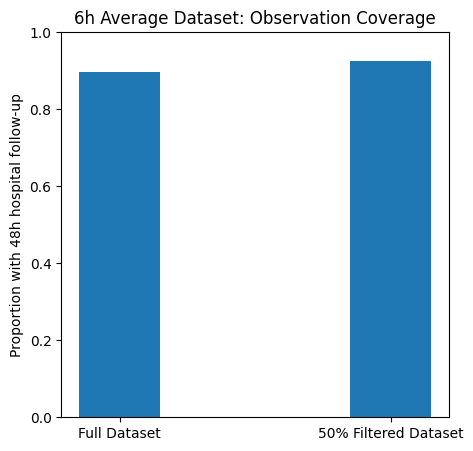

Full average dataset complete observation percentage: 89.61%
Filtered average dataset complete observation percentage: 92.60%


In [53]:
# Hospital observation coverage.
average_observation_rates = pd.Series({
    'Full Dataset': average_full_dataset['hospital_observed_48h'].mean(),
    '50% Filtered Dataset': average_filtered_dataset['hospital_observed_48h'].mean()
})
fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(average_observation_rates.index, average_observation_rates.values, width=0.3)
ax.set_ylabel('Proportion with 48h hospital follow-up')
ax.set_title(f'{INTERVAL}h Average Dataset: Observation Coverage')
ax.set_ylim(0, 1)
plt.show()
print(f'Full average dataset complete observation percentage: '
      f"{average_observation_rates['Full Dataset'] * 100:.2f}%")
print(f'Filtered average dataset complete observation percentage: '
      f"{average_observation_rates['50% Filtered Dataset'] * 100:.2f}%")

# 3. Models (Methods 2.3)

We compared tuned and untuned LR and XGBoost with random guessing and six-hour RSBI to predict recorded reintubation or in-hospital death within 48 hours of planned extubation.


### Inputs

- Six-hour data from the cells above, passed directly in memory.
- Filtered cohort: primary analysis. Full cohort: exploratory sensitivity analysis.


In [54]:
from datetime import datetime

# These tables are created in the extraction section above.
COHORT_DATA = {
    "filtered": average_filtered_dataset.copy(deep=True),
    "full": average_full_dataset.copy(deep=True),
}
COVERAGE_DATA = average_coverage.copy(deep=True)

### Settings (Table B.1)

- Seed: 42. Hyperparameters are defined below.
- We kept the primary analysis unchanged after test inspection. We added full-cohort sensitivity and untuned comparisons as exploratory analyses.


In [55]:
CONFIG = {
    "analysis_note": "We kept the primary analysis unchanged after test inspection; full-cohort sensitivity and untuned comparisons are exploratory.",
    "output_root": str(Path.cwd() / "models/outputs/six_hour_tuning_comparison_in_memory"),
    "target": "combined_outcome",
    "seed": 42,
    "split_mode": "temporal",
    "temporal_cutoff": 2020,  # same calendar-year boundary for every analysis
    "min_test_events": 20,    # warning only; all test patients are evaluated
    "feature_columns": None,  # None: use recognised physiological predictors; audit is saved
    "categorical_columns": ["gender", "sex", "first_careunit", "icu_type_at_admission"],
    "rsbi_column": None,      # None: use the six-hour RSBI mean
    "negative_followup_policy": "retain_recorded_labels",  # report uncertainty; do not redefine the cohort

    # Nested cross-validation and exhaustive grids (GridSearchCV).
    "outer_folds": 5,
    "inner_folds": 3,
    "lr_c_values": [0.001, 0.01, 0.1, 1, 10, 100],
    "lr_max_iter": 3000,
    "lr_fixed_c": 1.0,
    # Existing project starting settings, explicitly fixed; these are not XGBoost library defaults.
    "xgb_fixed_params": {"n_estimators": 250, "max_depth": 3, "learning_rate": 0.05,
        "min_child_weight": 1, "reg_lambda": 1},
    "xgb_param_grid": {       # 2 x 3 x 2 x 2 x 2 = 48 combinations
        "n_estimators": [200, 400],
        "max_depth": [2, 3, 4],
        "learning_rate": [0.03, 0.1],
        "min_child_weight": [1, 5],
        "reg_lambda": [1, 10],
    },
    "xgb_subsample": 0.8,
    "xgb_colsample_bytree": 0.8,
    "xgb_threads": 4,

    # Evaluation.
    "calibrate": True,
    "calibration_method": "sigmoid",
    "sensitivity_target": 0.80,            # exploratory threshold target, not clinically validated
    "decision_curve_max_threshold": 0.30,  # decision curve covers risk thresholds 1% to this value
    "bootstrap_replicates": 1000,
}

### Temporal split (Methods 2.3)

- Calendar intervals estimated from shifted extubation dates and anchor-year information: before 2020 for development, from 2020 for testing. Intervals crossing 2020 excluded.
- Identifiers, split fields and follow-up metadata excluded from predictors.
- Input checks cover duplicates, data consistency and extreme values. Range flags do not change measurements.


In [56]:
REQUIRED_CONFIG = {
    "cohort", "output_dir", "target", "seed", "split_mode",
    "temporal_cutoff", "min_test_events", "feature_columns", "categorical_columns",
    "rsbi_column", "outer_folds", "inner_folds", "lr_c_values", "lr_max_iter",
    "xgb_param_grid", "xgb_subsample", "xgb_colsample_bytree", "xgb_threads",
    "calibrate", "calibration_method", "sensitivity_target", "decision_curve_max_threshold",
    "bootstrap_replicates", "analysis",
    "suite_output_dir", "negative_followup_policy",
    "lr_fixed_c", "xgb_fixed_params", "analysis_note",
}

PHYSIOLOGY = {
    "heart_rate", "mbp", "sbp", "dbp", "resp_rate", "temperature", "spo2",
    "respiratory_rate_total", "respiratory_rate_spontaneous",
    "tidal_volume_observed", "tidal_volume_spontaneous", "fio2", "peep",
    "plateau_pressure", "minute_volume", "minute_ventilation", "po2", "pco2",
    "ph", "fio2_bg", "fio2_chartevents", "pao2fio2ratio", "bicarbonate",
    "baseexcess", "lactate", "rsbi",
}
BASELINE = {"age", "admission_age", "gender", "sex", "first_careunit", "icu_type_at_admission",
    "icu_hours_before_extubation", "hospital_hours_before_extubation"}
OUTCOME_COMPONENTS = ["death_within_48_hours", "reintubation_within_48_hours"]
TUNED_MODELS = ["logistic_regression", "xgboost"]
MODEL_NAMES = ["logistic_regression", "logistic_regression_untuned", "xgboost", "xgboost_untuned"]
PROBABILITY_MODELS = MODEL_NAMES  # calibrated risk predictions
SCORE_MODELS = MODEL_NAMES + ["random_guess"]  # random guessing is the proposal baseline
MODEL_PAIRS = [("xgboost", "logistic_regression"),
    ("logistic_regression", "logistic_regression_untuned"), ("xgboost", "xgboost_untuned")]

# Broad limits for error detection only: values outside them are counted and reported, never changed.
# Units follow the extraction notebook: FiO2 as a fraction, tidal volume in mL, temperature in degrees C.
PLAUSIBLE_RANGES = {
    "heart_rate": (20, 250), "mbp": (20, 200), "sbp": (40, 300), "dbp": (10, 200),
    "resp_rate": (1, 80), "respiratory_rate_total": (1, 80), "respiratory_rate_spontaneous": (1, 80),
    "temperature": (30, 43), "spo2": (50, 100),
    "tidal_volume_observed": (50, 2000), "tidal_volume_spontaneous": (50, 2000),
    "fio2": (0.21, 1.0), "fio2_bg": (0.21, 1.0), "fio2_chartevents": (0.21, 1.0),
    "peep": (0, 30), "plateau_pressure": (0, 60), "minute_volume": (0.5, 40), "minute_ventilation": (0.5, 40),
    "po2": (20, 700), "pco2": (10, 150), "ph": (6.8, 7.8), "pao2fio2ratio": (20, 1000),
    "bicarbonate": (2, 60), "baseexcess": (-40, 40), "lactate": (0.1, 30), "rsbi": (1, 1000),
    "age": (18, 110), "admission_age": (18, 110),
}


def validate_config(config):
    """Reject missing, unknown or inconsistent settings before modelling."""
    cfg = deepcopy(config)
    missing = sorted(REQUIRED_CONFIG - set(cfg))
    if missing:
        raise ValueError("CONFIG is missing: " + str(missing))
    unknown = sorted(set(cfg) - REQUIRED_CONFIG)
    if unknown:
        raise ValueError("Unknown CONFIG settings: " + str(unknown))
    if cfg["calibration_method"] not in {"sigmoid", "isotonic"}:
        raise ValueError("calibration_method must be 'sigmoid' or 'isotonic'.")
    if cfg["negative_followup_policy"] not in {"retain_recorded_labels", "require_complete_negatives"}:
        raise ValueError("Unknown negative_followup_policy.")
    if cfg["split_mode"] != "temporal" or cfg["temporal_cutoff"] is None:
        raise ValueError("These analyses require a common, explicit temporal cutoff.")
    if int(cfg["min_test_events"]) < 1:
        raise ValueError("min_test_events must be at least 1.")
    if not 0 < cfg["decision_curve_max_threshold"] < 1:
        raise ValueError("decision_curve_max_threshold must be between 0 and 1.")
    if int(cfg["bootstrap_replicates"]) < 10:
        raise ValueError("bootstrap_replicates must be at least 10; intervals are always reported.")
    if cfg["lr_fixed_c"] <= 0:
        raise ValueError("lr_fixed_c must be positive.")
    if set(cfg["xgb_fixed_params"]) != set(cfg["xgb_param_grid"]):
        raise ValueError("Fixed XGBoost settings must specify the same hyperparameters as the tuning grid.")
    return cfg


def make_run_configs(config):
    """Keep each notebook run separate from earlier results."""
    cfg = deepcopy(config)
    root = Path(cfg.pop("output_root")) / datetime.now().strftime("run_%Y%m%d_%H%M%S_%f")
    cfg["suite_output_dir"] = str(root)
    return {name: validate_config({**deepcopy(cfg), "analysis": name, "cohort": cohort,
        "output_dir": str(root / name)})
        for name, cohort in [("filtered_six_hour", "filtered"), ("full_six_hour", "full")]}


def write_json(path, value):
    """Save settings, converting NumPy scalars and paths to JSON values."""
    def encode(x):
        if isinstance(x, np.generic):
            return x.item()
        if isinstance(x, Path):
            return str(x)
        raise TypeError(f"Cannot encode {type(x)}")
    Path(path).write_text(json.dumps(value, indent=2, default=encode), encoding="utf-8")


def binary_series(s, name):
    """Require observed binary labels."""
    out = pd.to_numeric(s, errors="raise")
    if out.isna().any() or not out.isin([0, 1]).all():
        raise ValueError(f"{name} must contain only observed 0/1 labels.")
    return out.astype(int)


def forbidden_feature(name, target):
    """Identifiers, outcomes and post-prediction times must never be predictors."""
    n = name.lower()
    return (n == target.lower() or n in {"subject_id", "hadm_id", "stay_id", "dod", "label", "y"}
            or bool(re.search(r"outcome|death|deathtime|reintubat|discharg|dischtime|outtime|expire|los_|length_of_stay|followup|follow_up|hospital_observed|anchor_year|extubation_time|admittime|icu_intime|charttime|storetime|specimen_id|observed_values|missingness|retained_by", n)))


def feature_family(name):
    """Map a window summary (e.g. RSBI_mean_6h) to its variable (rsbi)."""
    return re.sub(r"(_bin_[0-5]|_(mean|std|sd|min|max|last|slope|count|missing)(?:_6h)?|_6h)$", "", name.lower())


def recognised_feature(name):
    """Static covariates and physiological variables are the default predictors."""
    return name.lower() in BASELINE or feature_family(name) in PHYSIOLOGY


def range_audit(df, columns):
    """Count predictor values outside PLAUSIBLE_RANGES; the data are not modified."""
    rows = []
    for c in columns:
        limits = PLAUSIBLE_RANGES.get(feature_family(c))
        if limits is None or not pd.api.types.is_numeric_dtype(df[c]):
            continue
        v = df[c].dropna()
        rows.append({"column": c, "lower_limit": limits[0], "upper_limit": limits[1],
            "observed": len(v), "below": int((v < limits[0]).sum()), "above": int((v > limits[1]).sum()),
            "min": v.min() if len(v) else np.nan, "max": v.max() if len(v) else np.nan})
    audit = pd.DataFrame(rows, columns=["column", "lower_limit", "upper_limit", "observed", "below", "above", "min", "max"])
    audit["implausible_fraction"] = (audit.below + audit.above) / audit.observed.replace(0, np.nan)
    return audit

In [57]:
def prepare_cohort(cfg):
    """Copy one in-memory cohort, check it and select predictors. Predictor values are not altered."""
    source = cfg["cohort"]
    if source not in COHORT_DATA:
        raise ValueError(f"Unknown in-memory cohort: {source}")
    df = COHORT_DATA[source].copy(deep=True)
    if df.columns.duplicated().any():
        raise ValueError("Duplicate cohort column names.")
    for column in ["subject_id", "stay_id", "hadm_id"]:
        if column in df:
            df[column] = df[column].astype("string")
    if "subject_id" not in df or cfg["target"] not in df:
        raise ValueError("Required columns: subject_id and " + cfg["target"])
    if df.subject_id.isna().any() or df.subject_id.duplicated().any():
        raise ValueError("Expected ONE row per subject_id, with a single index extubation.")
    # Keep splits reproducible if input rows are reordered.
    df = df.sort_values("subject_id").reset_index(drop=True)
    df[cfg["target"]] = binary_series(df[cfg["target"]], cfg["target"])
    components_present = [c in df for c in OUTCOME_COMPONENTS]
    if all(components_present):
        for c in OUTCOME_COMPONENTS:
            df[c] = binary_series(df[c], c)
        if not np.array_equal(df[cfg["target"]], df[OUTCOME_COMPONENTS].max(axis=1)):
            raise ValueError("combined_outcome disagrees with death OR reintubation.")
    else:
        warnings.warn("Outcome components are missing; cannot verify the combined label.")
    followup_col = next((c for c in ["hospital_observed_48h", "followup_complete"] if c in df), None)
    if followup_col:
        original = df[followup_col]
        known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,
            "true": 1, "false": 0}), errors="coerce")
        if (original.notna() & (known.isna() | ~known.isin([0, 1]))).any():
            raise ValueError(f"{followup_col} must contain 0/1, booleans or missing values.")
        df[followup_col] = known
    else:
        known = pd.Series(np.nan, index=df.index)
    incomplete_negative = df[cfg["target"]].eq(0) & known.ne(1)
    if cfg["negative_followup_policy"] == "require_complete_negatives" and incomplete_negative.any():
        raise ValueError("Negative labels lack complete follow-up. Resolve the phenotype; no rows were silently dropped.")
    requested = cfg.get("feature_columns")
    selected = list(requested) if requested is not None else [c for c in df if recognised_feature(c)]
    if not selected or len(set(selected)) != len(selected):
        raise ValueError("No recognised predictors or duplicate features. Set feature_columns explicitly.")
    if not set(selected).issubset(df.columns):
        raise ValueError("Feature columns missing: " + str(sorted(set(selected) - set(df.columns))))
    leaks = [c for c in selected if forbidden_feature(c, cfg["target"])]
    if leaks:
        raise ValueError("Forbidden identifier/outcome/future predictors: " + str(leaks))
    cats = [c for c in selected if c in cfg["categorical_columns"]]
    nums = [c for c in selected if c not in cats]
    if not nums:
        raise ValueError("No numeric physiological predictors selected.")
    # Type conversion only: infinite values cannot be imputed, so they are treated as missing.
    for c in nums:
        df[c] = pd.to_numeric(df[c], errors="raise").replace([np.inf, -np.inf], np.nan)
    for c in cats:
        df[c] = df[c].astype(object).where(df[c].notna(), np.nan)
    rsbi_candidates = [cfg["rsbi_column"]] if cfg.get("rsbi_column") else ["RSBI_mean_6h", "rsbi_mean_6h", "RSBI", "rsbi"]
    rsbi_col = next((c for c in rsbi_candidates if c in df), None)
    if cfg.get("rsbi_column") and rsbi_col is None:
        raise ValueError("Configured rsbi_column is absent.")
    if rsbi_col:
        df[rsbi_col] = pd.to_numeric(df[rsbi_col], errors="raise").replace([np.inf, -np.inf], np.nan)
    else:
        warnings.warn("No RSBI column; skipping the RSBI comparison.")
    return df, nums, cats, rsbi_col


def followup_summary(df, cfg):
    """Count labels without complete 48-hour hospital observation."""
    col = next((c for c in ["hospital_observed_48h", "followup_complete"] if c in df), None)
    observed = df[col].eq(1) if col else pd.Series(False, index=df.index)
    return {"followup_field": col, "patients": len(df),
        "negative_labels_without_complete_observation": int((df[cfg["target"]].eq(0) & ~observed).sum()),
        "known_events_without_complete_observation": int((df[cfg["target"]].eq(1) & ~observed).sum()),
        "policy": cfg["negative_followup_policy"]}

In [58]:
def make_split(df, cfg):
    """Assign each patient to development, test or ambiguous_time (excluded) by real calendar year."""
    manifest = df[["subject_id"]].copy()
    manifest["partition"] = "ambiguous_time"
    if cfg["split_mode"] == "temporal":
        required = ["extubation_time", "anchor_year", "anchor_year_group"]
        missing = [c for c in required if c not in df]
        if missing:
            raise ValueError("Temporal holdout needs " + str(missing) + ". Keep them in the cohort tables created above.")
        groups = df.anchor_year_group.astype(str).str.extract(r"^\s*(\d{4})\s*[-–]\s*(\d{4})\s*$").astype(float)
        anchor = pd.to_numeric(df.anchor_year, errors="coerce")
        year = pd.to_datetime(df.extubation_time, errors="coerce").dt.year
        if groups.isna().any().any() or anchor.isna().any() or year.isna().any():
            raise ValueError("Temporal metadata contain missing or invalid values.")
        if (groups[1] < groups[0]).any() or (anchor % 1 != 0).any():
            raise ValueError("Invalid anchor year or year-group interval.")
        offset = year - anchor
        # Map shifted extubation years to possible calendar-year intervals.
        manifest["possible_year_lower"] = (groups[0] + offset).astype(int)
        manifest["possible_year_upper"] = (groups[1] + offset).astype(int)
        cutoff = cfg["temporal_cutoff"]
        manifest.loc[manifest.possible_year_upper < cutoff, "partition"] = "development"
        manifest.loc[manifest.possible_year_lower >= cutoff, "partition"] = "test"
        split_note = {"mode": "temporal", "cutoff": int(cutoff), "rule": "development: upper possible year < cutoff; test: lower possible year >= cutoff; overlapping intervals excluded", "cutoff_choice": "explicit, chosen without model performance"}
    else:
        raise ValueError("split_mode must be temporal.")
    dev = np.flatnonzero(manifest.partition.eq("development"))
    test = np.flatnonzero(manifest.partition.eq("test"))
    if not len(dev) or not len(test):
        raise ValueError("Empty development/test set. Check year intervals and temporal_cutoff.")
    assert not set(df.iloc[dev].subject_id) & set(df.iloc[test].subject_id)
    # Validate fold sizes using development labels only.
    checked_cv(df.iloc[dev][cfg["target"]].to_numpy(), cfg["outer_folds"], cfg["seed"])
    return manifest, dev, test, split_note


def checked_cv(y, folds, seed):
    """Stratified folds, after checking each class has enough patients."""
    counts = np.bincount(np.asarray(y, dtype=int), minlength=2)
    if folds < 2 or min(counts) < folds:
        raise ValueError(f"Need at least {folds} patients in each class for cross-validation; found {counts.tolist()}.")
    return list(StratifiedKFold(folds, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))


def holdout_status(df, test_idx, cfg):
    """Count test patients and events only; no model is applied to the holdout here."""
    y = df.iloc[test_idx][cfg["target"]]
    events, non_events = int(y.sum()), int(len(y) - y.sum())
    return {"test_patients": len(y), "test_events": events,
        "test_non_events": non_events,
        "small_sample_warning": min(events, non_events) < cfg["min_test_events"],
        "rule": f"warn below {cfg['min_test_events']} events or non-events; retain all test patients"}


def warn_small_holdout(status, cfg):
    """Low event counts affect precision, not eligibility for evaluation."""
    if status["small_sample_warning"]:
        warnings.warn(f"{cfg['analysis']}: temporal holdout has {status['test_events']} events and "
            f"{status['test_non_events']} non-events (warning threshold: {cfg['min_test_events']}). "
            "All test patients are retained. Estimates and bootstrap intervals may be unstable; "
            "metrics requiring both outcome classes are undefined if one class is absent.")


def check_inputs(config):
    """Check inputs, fold sizes and holdout size without training or scoring test patients."""
    cfg = validate_config(config)
    df, nums, cats, rsbi_col = prepare_cohort(cfg)
    manifest, dev, test, _ = make_split(df, cfg)
    y = df.iloc[dev][cfg["target"]].to_numpy()
    for fold, (train, _) in enumerate(checked_cv(y, cfg["outer_folds"], cfg["seed"])):
        checked_cv(y[train], cfg["inner_folds"], cfg["seed"] + fold + 1)
    holdout = holdout_status(df, test, cfg)
    warn_small_holdout(holdout, cfg)
    audit = range_audit(df, nums)
    return {"patients": len(df), "development_patients": len(dev),
        "development_events": int(y.sum()), "test_patients": holdout["test_patients"],
        "test_events": holdout["test_events"], "test_non_events": holdout["test_non_events"],
        "small_holdout_warning": holdout["small_sample_warning"],
        "excluded_ambiguous_year": int(manifest.partition.eq("ambiguous_time").sum()),
        "predictors": len(nums) + len(cats), "events_per_predictor": round(y.sum() / (len(nums) + len(cats)), 2),
        "values_outside_plausible_range": int(audit.below.sum() + audit.above.sum()),
        "rsbi_comparator": rsbi_col, "outer_folds": cfg["outer_folds"], "inner_folds": cfg["inner_folds"],
        "calibration": cfg["calibration_method"] if cfg["calibrate"] else "disabled",
        "development_negatives_without_complete_followup": followup_summary(df.iloc[dev], cfg)["negative_labels_without_complete_observation"]}


def validate_coverage(filtered, full):
    """Check the supplied missingness audit; do not apply a new patient filter."""
    coverage = COVERAGE_DATA.copy(deep=True)
    if coverage.columns.duplicated().any():
        raise ValueError("Duplicate coverage column names.")
    for column in ["subject_id", "stay_id", "hadm_id"]:
        if column in coverage:
            coverage[column] = coverage[column].astype("string")
    if coverage.subject_id.isna().any() or coverage.subject_id.duplicated().any():
        raise ValueError("Coverage must contain one row per subject_id.")
    if set(coverage.subject_id) != set(full.subject_id):
        raise ValueError("Coverage and full cohort must contain the same patients.")
    coverage = coverage.set_index("subject_id").loc[full.subject_id].reset_index()
    if not coverage.stay_id.equals(full.stay_id):
        raise ValueError("Coverage and full cohort refer to different ICU stays.")
    retained = coverage.retained_by_missingness_filter.map({True: True, False: False,
        "True": True, "False": False, "true": True, "false": False})
    if retained.isna().any() or set(coverage.loc[retained, "subject_id"]) != set(filtered.subject_id):
        raise ValueError("Coverage retention flags do not match the supplied filtered cohort.")
    means = [c for c in full if c.endswith("_mean_6h") and feature_family(c) in PHYSIOLOGY]
    if not means:
        raise ValueError("No six-hour mean features found in the averaged cohort tables.")
    if not np.allclose(full[means].isna().mean(axis=1), coverage.average_feature_missingness):
        raise ValueError("Coverage missingness disagrees with the averaged features.")
    for c in means:
        count = c.removesuffix("_mean_6h") + "_observed_values_6h"
        if count not in coverage:
            raise ValueError(f"Coverage is missing {count}.")
        observed = pd.to_numeric(coverage[count], errors="raise")
        if observed.isna().any() or (observed < 0).any() or (observed % 1 != 0).any():
            raise ValueError(f"Coverage counts must be non-negative integers: {count}.")
        if not np.array_equal(observed.eq(0), full[c].isna()):
            raise ValueError(f"Coverage counts disagree with missing values in {c}.")
    return {"full_patients": len(full), "filtered_patients": len(filtered),
        "removed_by_supplied_filter": len(full) - len(filtered), "mean_features": len(means)}


def prepare_analyses(configs):
    """Lock shared predictors and check that cohorts represent the same index events."""
    configs = deepcopy(configs)
    main = configs["filtered_six_hour"]
    filtered, nums, cats, _ = prepare_cohort(main)
    features = nums + cats
    full, full_nums, full_cats, _ = prepare_cohort(configs["full_six_hour"])
    coverage_summary = validate_coverage(filtered, full)
    print("Six-hour input validation:", coverage_summary)
    if set(features) != set(full_nums + full_cats):
        raise ValueError("Filtered and full cohorts must have the same predictor definitions.")
    if not set(filtered.subject_id).issubset(set(full.subject_id)):
        raise ValueError("The filtered cohort must be a subset of the full eligible cohort.")
    shared = full.set_index("subject_id").loc[filtered.subject_id].reset_index()
    optional = ["stay_id", "hadm_id", *OUTCOME_COMPONENTS, "hospital_observed_48h", "followup_complete"]
    one_sided = [c for c in optional if (c in filtered) != (c in full)]
    if one_sided:
        raise ValueError("Columns present in only one cohort table: " + str(one_sided))
    temporal = ["extubation_time", "anchor_year", "anchor_year_group"]
    check_columns = features + [main["target"]] + [c for c in temporal if c in filtered and c in full]
    check_columns += [c for c in optional if c in filtered]
    try:
        pd.testing.assert_frame_equal(filtered[check_columns].reset_index(drop=True),
            shared[check_columns].reset_index(drop=True), check_dtype=False,
            check_exact=False, rtol=1e-8, atol=1e-10)
    except AssertionError:
        raise ValueError("Shared patients have inconsistent features, outcomes or index-event metadata across the two cohort tables.") from None
    for cfg in [configs["filtered_six_hour"], configs["full_six_hour"]]:
        cfg["feature_columns"] = features.copy()
    main_manifest, _, _, _ = make_split(filtered, main)
    full_manifest, _, _, _ = make_split(full, configs["full_six_hour"])
    matching = full_manifest.set_index("subject_id").loc[filtered.subject_id, "partition"].to_numpy()
    if not np.array_equal(main_manifest.partition.to_numpy(), matching):
        raise ValueError("Shared patients must have the same temporal partition in both cohorts.")
    return configs


def environment_versions():
    """Package versions saved with every analysis."""
    versions = {p: importlib.metadata.version(p) for p in
        ["numpy", "pandas", "scikit-learn", "xgboost", "scipy", "matplotlib", "joblib",
         "google-cloud-bigquery", "db-dtypes", "pyarrow", "google-auth", "ipython"]}
    return {**versions, "python": platform.python_version()}

In [59]:
RUN_CONFIGS = make_run_configs(CONFIG)
RUN_CONFIGS = prepare_analyses(RUN_CONFIGS)
SUITE_DIR = Path(next(iter(RUN_CONFIGS.values()))["suite_output_dir"])
SUITE_DIR.mkdir(parents=True, exist_ok=True)
print("Results folder:", SUITE_DIR)

# One row per analysis: cohort size, events, holdout feasibility and data-quality counts.
INPUT_CHECKS = pd.DataFrame({name: check_inputs(cfg) for name, cfg in RUN_CONFIGS.items()}).T
INPUT_CHECKS.to_csv(SUITE_DIR / "input_checks.csv")
display(INPUT_CHECKS)
print("Package versions:", environment_versions())

# Error detection for the extraction step: implausible values are counted, not changed.
# The full cohort contains every filtered patient, so one audit covers both.
_full, _full_nums = prepare_cohort(RUN_CONFIGS["full_six_hour"])[:2]
RANGE_AUDIT = range_audit(_full, _full_nums)
RANGE_AUDIT.to_csv(SUITE_DIR / "predictor_range_audit_full_cohort.csv", index=False)
flagged = RANGE_AUDIT[(RANGE_AUDIT.below + RANGE_AUDIT.above) > 0]
if len(flagged):
    warnings.warn(f"{len(flagged)} predictor columns contain values outside PLAUSIBLE_RANGES; report them to the extraction step.")
    display(flagged.sort_values("implausible_fraction", ascending=False))

Six-hour input validation: {'full_patients': 18620, 'filtered_patients': 16859, 'removed_by_supplied_filter': 1761, 'mean_features': 19}


C:\Users\22110\AppData\Local\Temp\ipykernel_47876\2084602672.py:30: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,
C:\Users\22110\AppData\Local\Temp\ipykernel_47876\2084602672.py:30: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,


Results folder: c:\Users\22110\Documents\Machine Learning Applications for Health\comp90089-ml-in-health-group-25\models\outputs\six_hour_tuning_comparison_in_memory\run_20261025_223652_711303


C:\Users\22110\AppData\Local\Temp\ipykernel_47876\2084602672.py:30: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,
C:\Users\22110\AppData\Local\Temp\ipykernel_47876\2084602672.py:30: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,


,patients,development_patients,development_events,test_patients,test_events,test_non_events,small_holdout_warning,excluded_ambiguous_year,predictors,events_per_predictor,values_outside_plausible_range,rsbi_comparator,outer_folds,inner_folds,calibration,development_negatives_without_complete_followup
filtered_six_hour,16859,15241,1402,880,96,784,False,738,24,58.42,156,RSBI_mean_6h,5,3,sigmoid,478
full_six_hour,18620,16685,1888,1064,146,918,False,871,24,78.67,167,RSBI_mean_6h,5,3,sigmoid,639


Package versions: {'numpy': '2.3.1', 'pandas': '2.3.3', 'scikit-learn': '1.9.0', 'xgboost': '3.2.0', 'scipy': '1.16.0', 'matplotlib': '3.10.3', 'joblib': '1.5.1', 'google-cloud-bigquery': '3.45.2', 'db-dtypes': '1.7.1', 'pyarrow': '21.0.0', 'google-auth': '2.58.0', 'ipython': '9.4.0', 'python': '3.13.5'}


C:\Users\22110\AppData\Local\Temp\ipykernel_47876\2084602672.py:30: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,
C:\Users\22110\AppData\Local\Temp\ipykernel_47876\4017081768.py:20: UserWarning: 10 predictor columns contain values outside PLAUSIBLE_RANGES; report them to the extraction step.
  warnings.warn(f"{len(flagged)} predictor columns contain values outside PLAUSIBLE_RANGES; report them to the extraction step.")


,column,lower_limit,upper_limit,observed,below,above,min,max,implausible_fraction
16,bicarbonate_mean_6h,2.0,60.0,26,0,1,12.500000,97.000000,0.038462
7,tidal_volume_spontaneous_mean_6h,50.0,2000.0,14553,29,72,1.070000,580221.000000,0.006940
12,RSBI_mean_6h,1.0,1000.0,13244,6,18,0.436144,29230.769231,0.001812
8,tidal_volume_observed_mean_6h,50.0,2000.0,17702,16,3,1.300000,250264.000000,0.001073
6,respiratory_rate_spontaneous_mean_6h,1.0,80.0,14172,0,7,1.000000,470.000000,0.000494
9,minute_volume_mean_6h,0.5,40.0,18115,1,4,0.010000,391.300000,0.000276
5,spo2_mean_6h,50.0,100.0,18563,5,0,36.000000,100.000000,0.000269
4,temperature_mean_6h,30.0,43.0,16347,2,0,26.110000,41.330000,0.000122
10,peep_mean_6h,0.0,30.0,18208,0,2,0.000000,45.000000,0.000110
15,po2_mean_6h,20.0,700.0,10479,1,0,16.000000,566.000000,0.000095


### Cohort flow (Methods 2.1, Figure 1)

Unique patients after each exclusion and the temporal split. Missingness is based on 19 physiological summaries.


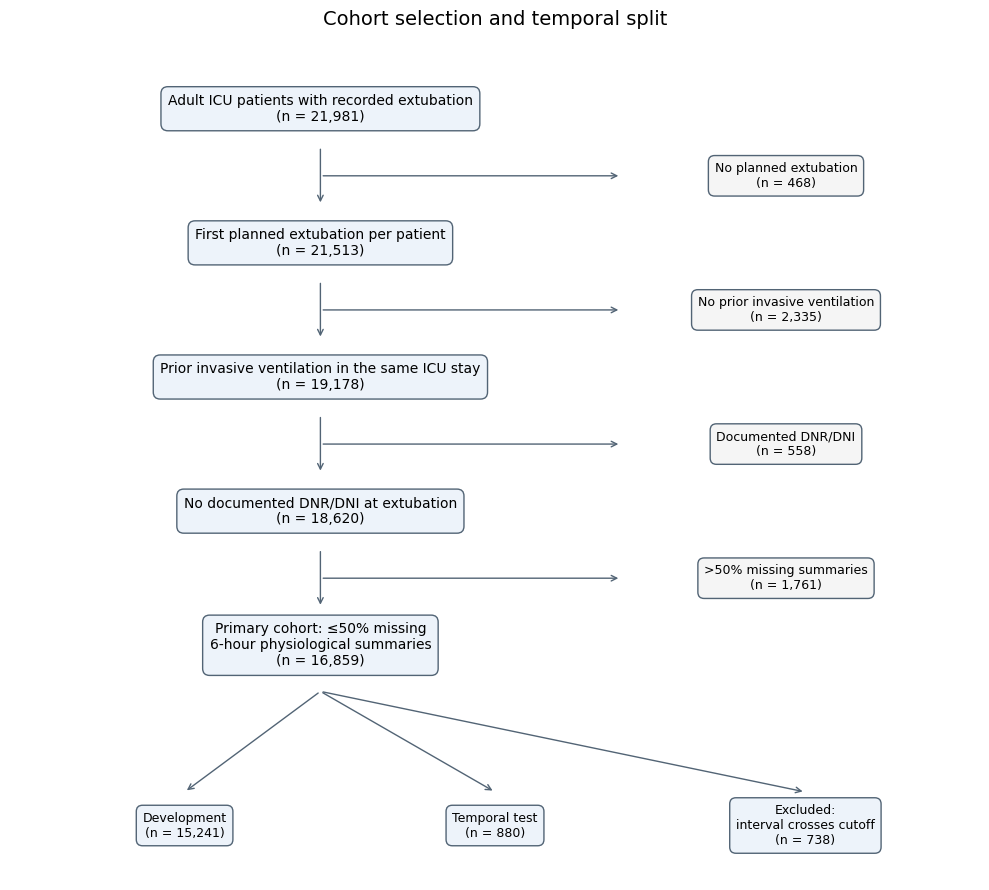

In [60]:
# All counts are unique patients, taken from the extraction and split checks above.
flow_counts = average_counts_result.set_index("Step")["Patients"].astype(int)
flow_split = INPUT_CHECKS.loc["filtered_six_hour"]
flow_partitions = {
    "Development": int(flow_split["development_patients"]),
    "Temporal test": int(flow_split["test_patients"]),
    "Excluded: interval crosses cutoff": int(flow_split["excluded_ambiguous_year"]),
}
assert flow_counts.loc[3] == flow_counts.loc[4], "Selecting the first planned event should retain each patient."
assert flow_counts.loc[6] == int(INPUT_CHECKS.loc["full_six_hour", "patients"])
assert flow_counts.loc[7] == int(flow_split["patients"])
assert flow_counts.loc[7] == sum(flow_partitions.values()), "Temporal partitions must sum to the primary cohort."

flow_stages = [
    ("Adult ICU patients with recorded extubation", flow_counts.loc[2]),
    ("First planned extubation per patient", flow_counts.loc[4]),
    ("Prior invasive ventilation in the same ICU stay", flow_counts.loc[5]),
    ("No documented DNR/DNI at extubation", flow_counts.loc[6]),
    (f"Primary cohort: ≤{MISSING:.0%} missing\n{INTERVAL}-hour physiological summaries", flow_counts.loc[7]),
]
flow_exclusions = [
    "No planned extubation", "No prior invasive ventilation",
    "Documented DNR/DNI", f">{MISSING:.0%} missing summaries",
]
assert all(before[1] >= after[1] for before, after in zip(flow_stages, flow_stages[1:]))

fig, ax = plt.subplots(figsize=(10, 9))
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis("off")


def flow_box(x, y, label, count, colour="#edf3fa", fontsize=10):
    ax.text(x, y, f"{label}\n(n = {count:,})", ha="center", va="center", fontsize=fontsize,
            bbox={"boxstyle": "round,pad=0.5", "facecolor": colour, "edgecolor": "#526475"})


flow_y = [0.92, 0.76, 0.60, 0.44, 0.28]
for index, ((label, count), y) in enumerate(zip(flow_stages, flow_y)):
    flow_box(0.32, y, label, count)
    if index:
        previous_y = flow_y[index - 1]
        midpoint = (previous_y + y) / 2
        ax.annotate("", xy=(0.32, y + 0.045), xytext=(0.32, previous_y - 0.045),
                    arrowprops={"arrowstyle": "->", "color": "#526475"})
        ax.annotate("", xy=(0.63, midpoint), xytext=(0.32, midpoint),
                    arrowprops={"arrowstyle": "->", "color": "#526475"})
        removed = flow_stages[index - 1][1] - count
        flow_box(0.80, midpoint, flow_exclusions[index - 1], removed, "#f5f5f5", 9)

for x, (label, count) in zip([0.18, 0.50, 0.82], flow_partitions.items()):
    ax.annotate("", xy=(x, 0.105), xytext=(0.32, 0.225),
                arrowprops={"arrowstyle": "->", "color": "#526475"})
    flow_box(x, 0.065, label.replace(": ", ":\n"), count, fontsize=9)
ax.set_title("Cohort selection and temporal split", fontsize=14, pad=12)
fig.tight_layout()
for extension in ["png", "pdf"]:
    fig.savefig(SUITE_DIR / f"cohort_flowchart.{extension}", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

cohort_flow_counts = average_counts_result.copy()
cohort_flow_counts.to_csv(SUITE_DIR / "cohort_flow_counts.csv", index=False)
pd.DataFrame(flow_partitions.items(), columns=["partition", "patients"]).to_csv(
    SUITE_DIR / "cohort_flow_partitions.csv", index=False)


### Study timeline (Methods 2.2)

Six-hour predictor window and 48-hour outcome window around extubation.


In [61]:
def plot_study_timeline(folder):
    """Timeline figure: predictor window, prediction time and outcome window (hours from extubation)."""
    fig, (before, after) = plt.subplots(1, 2, figsize=(10, 2.6), sharey=True,
        gridspec_kw={"width_ratios": [1, 1.6], "wspace": 0.04})
    before.axvspan(-6, 0, color="tab:blue", alpha=.2)
    before.text(-3.5, .7, "Predictors\nsix-hour means\n[t − 6 h, t)", ha="center", va="center", fontsize=9)
    before.set(xlim=(-6.3, 0), xticks=range(-6, 1), ylim=(0, 1), yticks=[])
    after.axvspan(0, 48, color="tab:red", alpha=.15)
    after.text(24, .6, "Outcome window (t, t + 48 h]\nreintubation or death", ha="center", va="center", fontsize=9)
    after.text(1, .12, "t = planned extubation: prediction time, no gap", fontsize=8)
    after.set(xlim=(0, 48.5), xticks=[12, 24, 36, 48])  # 0 is labelled on the left panel
    for ax in (before, after):
        ax.axvline(0, color="k", lw=2)
        for side in ["left", "right", "top"]:
            ax.spines[side].set_visible(False)
    fig.supxlabel("Hours relative to planned extubation (t)", fontsize=9, y=-0.06)
    fig.savefig(folder / "study_timeline.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def describe_group(d, features, target):
    """Table A.4 column for one group of patients."""
    def pct(mask):
        return f"{int(mask.sum())} ({100 * mask.mean():.1f}%)" if len(d) else ""
    def median_iqr(values, digits):
        q = values.quantile([.25, .5, .75])
        return f"{q[.5]:.{digits}f} [{q[.25]:.{digits}f}–{q[.75]:.{digits}f}]"
    row = {"Patients, n": str(len(d))}
    age_col = next((c for c in ["admission_age", "age"] if c in d), None)
    if age_col and len(d):
        row["Age, median [IQR]"] = median_iqr(d[age_col], 0)
    sex_col = next((c for c in ["gender", "sex"] if c in d), None)
    if sex_col:
        row["Female, n (%)"] = pct(d[sex_col].astype(str).str.upper().str.startswith("F"))
    for c, label in [("icu_hours_before_extubation", "ICU hours before extubation"),
                     ("hospital_hours_before_extubation", "Hospital hours before extubation")]:
        if c in d and len(d):
            row[label + ", median [IQR]"] = median_iqr(d[c], 1)
    icu = next((c for c in ["icu_type_at_admission", "first_careunit"] if c in d), None)
    if icu:
        for category, count in d[icu].value_counts(sort=False).items():  # categories keep cohort order
            row[f"ICU type: {category}, n (%)"] = f"{count} ({100 * count / len(d):.1f}%)"
    row["Extubation failure, n (%)"] = pct(d[target].eq(1))
    for c, label in [("death_within_48_hours", "  Death within 48 h"),
                     ("reintubation_within_48_hours", "  Reintubation within 48 h")]:
        if c in d:
            row[label + ", n (%)"] = pct(d[c].eq(1))
    followup_col = next((c for c in ["hospital_observed_48h", "followup_complete"] if c in d), None)
    if followup_col:
        row["Negative labels without complete 48-h observation, n"] = str(int((d[target].eq(0) & d[followup_col].ne(1)).sum()))
    row["Model predictors missing, mean %"] = f"{100 * d[features].isna().to_numpy().mean():.1f}" if len(d) else ""
    return row


def cohort_table(runs):
    """Table A.4: primary development/test cohorts, excluded patients and the full cohort."""
    primary, full = runs["filtered_six_hour"], runs["full_six_hour"]
    bundle = primary["bundle"]
    target = bundle["frozen"]["config"]["target"]
    features = bundle["frozen"]["selected_features"]
    everyone = full["data"].copy()
    icu = next((c for c in ["icu_type_at_admission", "first_careunit"] if c in everyone), None)
    if icu:
        # ICU types with fewer than 20 patients overall are grouped for display.
        counts = everyone[icu].value_counts()
        grouped = everyone[icu].where(everyone[icu].isin(counts[counts >= 20].index), "Other")
        everyone[icu] = pd.Categorical(grouped, categories=grouped.value_counts().index)
    everyone = everyone.set_index("subject_id", drop=False)
    removed = ~everyone.subject_id.isin(primary["data"].subject_id)
    groups = {"Development": everyone.loc[bundle["development_ids"]],
              "Temporal test": everyone.loc[bundle["test_ids"]],
              "Removed by missingness filter (all years)": everyone.loc[removed],
              "Full eligible cohort (all years)": everyone}
    table = pd.DataFrame({name: describe_group(d, features, target) for name, d in groups.items()})
    return table.fillna("0 (0.0%)").rename_axis("Characteristic").reset_index()

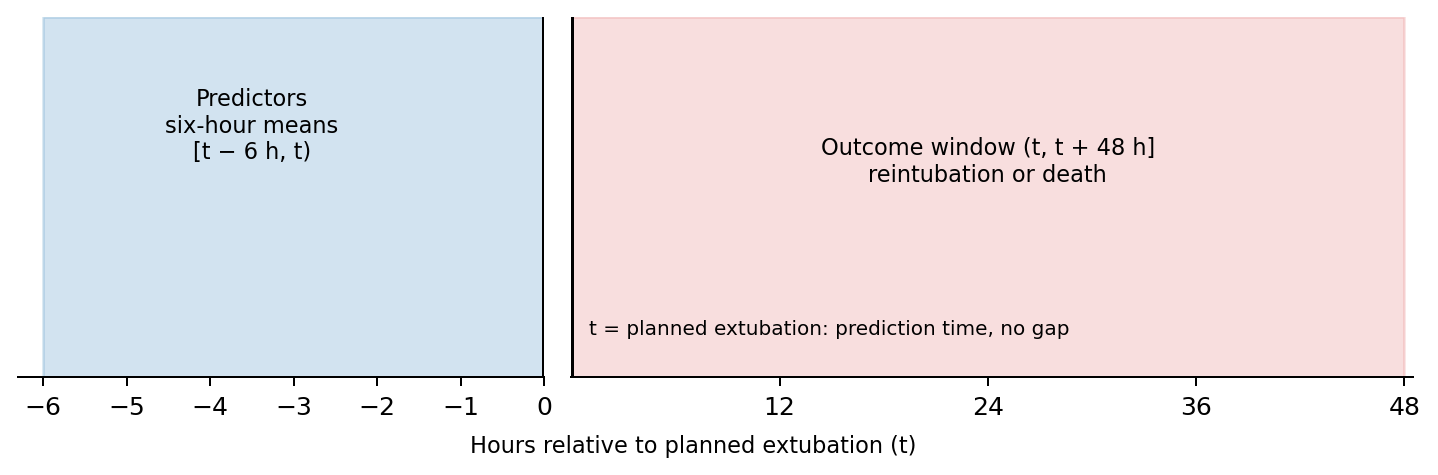

In [62]:
plot_study_timeline(SUITE_DIR)
display(Image(filename=str(SUITE_DIR / "study_timeline.png")))

### Preprocessing and fitting (Methods 2.3)

- Median imputation and categorical encoding fitted within training folds; numerical features standardised for LR.
- Class weights: balanced for LR; training negative-to-positive ratio for XGBoost.
- Sigmoid calibration using cross-validated predictions within the training partition.


In [63]:
class FoldBalancedXGB(ClassifierMixin, BaseEstimator):
    """XGBoost whose scale_pos_weight is recalculated from each training fold."""
    def __init__(self, n_estimators=250, max_depth=3, learning_rate=0.05,
                 min_child_weight=1, reg_lambda=1, subsample=0.8,
                 colsample_bytree=0.8, random_state=42, n_jobs=4):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.min_child_weight = min_child_weight
        self.reg_lambda = reg_lambda
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        counts = np.bincount(np.asarray(y, dtype=int), minlength=2)
        if min(counts) == 0:
            raise ValueError("XGBoost fit requires both classes.")
        # Negative/positive ratio of this training fold only.
        self.scale_pos_weight_ = float(counts[0] / counts[1])
        self.model_ = XGBClassifier(**self.get_params(), scale_pos_weight=self.scale_pos_weight_,
            objective="binary:logistic", eval_metric="logloss", tree_method="hist", device="cpu")
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        self.n_features_in_ = self.model_.n_features_in_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)


def model_pipeline(name, nums, cats, cfg):
    """Fold-wise preprocessing and model. Entirely missing training columns are kept (imputed as 0)."""
    numeric = [("impute", SimpleImputer(strategy="median", keep_empty_features=True))]
    if name == "logistic_regression":
        numeric.append(("scale", StandardScaler()))
    parts = [("numeric", Pipeline(numeric), nums)]
    if cats:
        categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="unknown", keep_empty_features=True)),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
        parts.append(("categorical", categorical, cats))
    prep = ColumnTransformer(parts, remainder="drop", sparse_threshold=0)
    if name == "logistic_regression":
        model = LogisticRegression(class_weight="balanced", solver="lbfgs", max_iter=cfg["lr_max_iter"], random_state=cfg["seed"])
    elif name == "xgboost":
        model = FoldBalancedXGB(random_state=cfg["seed"], n_jobs=cfg["xgb_threads"],
            subsample=cfg["xgb_subsample"], colsample_bytree=cfg["xgb_colsample_bytree"])
    else:
        raise ValueError(name)
    return Pipeline([("preprocess", prep), ("model", model)])


def fit_model(name, X, y, nums, cats, cfg, cv):
    """Fit fixed or searched hyperparameters, then apply the same training-only calibration."""
    family = name.removesuffix("_untuned")
    pipe = model_pipeline(family, nums, cats, cfg)
    if name in TUNED_MODELS:
        grid = ({"model__C": cfg["lr_c_values"]} if family == "logistic_regression"
                else {"model__" + key: values for key, values in cfg["xgb_param_grid"].items()})
        search = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", refit=True,
            n_jobs=1, error_score="raise")
        search.fit(X, y)
        params = search.best_params_
        fitted = search.best_estimator_
    else:
        fixed = {"C": cfg["lr_fixed_c"]} if family == "logistic_regression" else cfg["xgb_fixed_params"]
        params = {"model__" + key: value for key, value in fixed.items()}
        fitted = pipe.set_params(**params)
    if cfg["calibrate"]:
        # Calibrator uses training-partition OOF scores; base model is then refitted on that partition.
        fitted = CalibratedClassifierCV(clone(fitted), method=cfg["calibration_method"],
            cv=cv, ensemble=False, n_jobs=1)
        fitted.fit(X, y)
    elif name not in TUNED_MODELS:
        fitted.fit(X, y)
    return fitted, params

### Evaluation (Methods 2.4)

- AUROC, AP, sensitivity, specificity, PPV, NPV, Brier scores and calibration.
- 95% confidence intervals from 1,000 patient-bootstrap resamples; calibration slope and observed:expected ratio are point estimates.
- Thresholds: highest specificity at sensitivity ≥80% in development out-of-fold predictions, then fixed for testing.
- RSBI comparisons and decision curves use the same RSBI-available patients. Six-hour mean RSBI ≥105 is the adapted clinical comparator.


In [64]:
LABELS = {"logistic_regression": "LR (tuned)", "logistic_regression_untuned": "LR (untuned)",
    "xgboost": "XGBoost (tuned)", "xgboost_untuned": "XGBoost (untuned)",
    "random_guess": "Random guessing",
    "rsbi": "RSBI (continuous)", "rsbi_ge_105": "RSBI ≥ 105",
    "treat_all": "Act on all", "treat_none": "Act on none"}
COLOURS = {"logistic_regression": "tab:blue", "logistic_regression_untuned": "tab:blue",
    "xgboost": "tab:orange", "xgboost_untuned": "tab:orange",
    "random_guess": "#8c564b", "rsbi": "tab:green", "rsbi_ge_105": "tab:green",
    "treat_all": "grey", "treat_none": "black"}
LINESTYLES = {name: "--" if name.endswith("_untuned") or name.startswith("treat") else "-"
    for name in LABELS}
MARKERS = {name: "s" if name.endswith("_untuned") else "o" for name in LABELS}


def safe_ratio(a, b):
    return float(a / b) if b else np.nan


def calibration_summary(y, p):
    """Observed:expected ratio and calibration slope (outcome regressed on logit risk)."""
    p = np.clip(p, 1e-7, 1 - 1e-7)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    oe = safe_ratio(y.sum(), p.sum())
    if len(np.unique(y)) < 2 or np.std(logit) < 1e-12:
        return oe, np.nan
    # A very large C makes this effectively an unpenalised logistic regression.
    slope = LogisticRegression(C=1e10, max_iter=1000).fit(logit, y).coef_[0, 0]
    return oe, float(slope)


def metrics(y, score, threshold=0.5, probability=True, calibration=True):
    """Discrimination, threshold and (for probabilities) calibration metrics."""
    y, score = np.asarray(y, int), np.asarray(score, float)
    keep = np.isfinite(score)
    y, score = y[keep], score[keep]
    if not len(y):
        return {"n": 0}
    two = len(np.unique(y)) == 2
    prevalence = float(y.mean())
    tn, fp, fn, tp = confusion_matrix(y, score >= threshold, labels=[0, 1]).ravel()
    result = {"n": len(y), "events": int(y.sum()), "prevalence": prevalence,
        "auroc": roc_auc_score(y, score) if two else np.nan,
        "average_precision": average_precision_score(y, score) if two else np.nan,
        "threshold": float(threshold), "sensitivity": safe_ratio(tp, tp + fn),
        "specificity": safe_ratio(tn, tn + fp), "ppv": safe_ratio(tp, tp + fp),
        "npv": safe_ratio(tn, tn + fn), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "brier": np.nan, "scaled_brier": np.nan, "log_loss": np.nan,
        "observed_expected_ratio": np.nan, "calibration_slope": np.nan}
    if probability:
        result["brier"] = brier_score_loss(y, score)
        result["scaled_brier"] = 1 - result["brier"] / (prevalence * (1 - prevalence)) if two else np.nan
        result["log_loss"] = log_loss(y, np.clip(score, 1e-7, 1 - 1e-7), labels=[0, 1])
        if calibration:
            result["observed_expected_ratio"], result["calibration_slope"] = calibration_summary(y, score)
    return result


def choose_threshold(y, score, sensitivity_target):
    """Maximise specificity at the target sensitivity using development OOF scores."""
    if not 0 < sensitivity_target <= 1:
        raise ValueError("sensitivity_target must be in (0,1].")
    fpr, tpr, thresholds = roc_curve(y, score, drop_intermediate=False)
    eligible = np.flatnonzero((tpr >= sensitivity_target) & np.isfinite(thresholds))
    # roc_curve thresholds descend: among tied FPR choose the highest threshold.
    best = eligible[np.argmin(fpr[eligible])]
    return float(thresholds[best])


def prediction_table(df, cfg, scores, rsbi_col, fold=None):
    """One row per patient: labels, evaluation-only descriptors and every model's score."""
    cols = [c for c in ["subject_id", "hadm_id", "stay_id", cfg["target"], *OUTCOME_COMPONENTS,
        "age", "admission_age", "gender", "sex"] if c in df]
    out = df[cols].copy().reset_index(drop=True)
    out = out.rename(columns={cfg["target"]: "y_true"})
    for name, values in scores.items():
        out[name] = values
    if rsbi_col:
        out["rsbi"] = df[rsbi_col].to_numpy()
    if fold is not None:
        out["outer_fold"] = fold
    return out


def comparison_tables(predictions, thresholds, calibration=True):
    """Metrics for every model on all patients and on the RSBI-available subset."""
    rows = []
    scopes = {"all_patients": np.ones(len(predictions), dtype=bool)}
    if "rsbi" in predictions:
        scopes["rsbi_available_same_patients"] = np.isfinite(predictions.rsbi)
    for scope, mask in scopes.items():
        p = predictions.loc[mask]
        for name in SCORE_MODELS:
            if name in p:
                # Calibration metrics apply to probability models only.
                rows.append({"scope": scope, "model": name, **metrics(p.y_true, p[name],
                    thresholds.get(name, 0.5), name in PROBABILITY_MODELS, calibration)})
        if scope == "rsbi_available_same_patients":
            rows.append({"scope": scope, "model": "rsbi", **metrics(p.y_true, p.rsbi, 105, False)})
    return pd.DataFrame(rows)


def bootstrap_intervals(p, thresholds, cfg):
    """Patient-bootstrap intervals and paired differences for the three model comparisons."""
    rng = np.random.default_rng(cfg["seed"] + 200)
    samples, differences = [], []
    for rep in range(cfg["bootstrap_replicates"]):
        sample = p.iloc[rng.integers(0, len(p), len(p))]
        table = comparison_tables(sample, thresholds, calibration=False)
        for _, row in table.iterrows():
            for metric in ["auroc", "average_precision", "sensitivity", "specificity", "ppv", "npv", "brier", "scaled_brier"]:
                samples.append({"replicate": rep, "scope": row.scope, "model": row.model,
                    "metric": metric, "value": row.get(metric, np.nan)})
        paired = table[table.scope.eq("all_patients")].set_index("model")
        for a, b in MODEL_PAIRS:
            for metric in ["auroc", "average_precision", "brier"]:
                differences.append({"model_a": a, "model_b": b, "metric": metric,
                    "value": paired.loc[a, metric] - paired.loc[b, metric]})

    def summarise(frame, groups):
        # Undefined single-class draws are omitted for that metric, with valid counts recorded.
        frame["value"] = frame["value"].where(np.isfinite(frame["value"]))
        return frame.groupby(groups).value.agg(valid_replicates="count",
            lower_95=lambda s: s.quantile(.025), upper_95=lambda s: s.quantile(.975)).reset_index()

    intervals = summarise(pd.DataFrame(samples), ["scope", "model", "metric"])
    paired_ci = summarise(pd.DataFrame(differences), ["model_a", "model_b", "metric"])
    point = comparison_tables(p, thresholds, calibration=False)
    point = point[point.scope.eq("all_patients")].set_index("model")
    paired_ci["n"], paired_ci["events"] = len(p), int(p.y_true.sum())
    paired_ci["a"] = [point.loc[r.model_a, r.metric] for r in paired_ci.itertuples()]
    paired_ci["b"] = [point.loc[r.model_b, r.metric] for r in paired_ci.itertuples()]
    paired_ci["a_minus_b"] = paired_ci.a - paired_ci.b
    return intervals, paired_ci


def paired_bootstrap(y, a, b, reps, seed):
    """Metrics of scores a and b and their difference (a − b) on the same resampled patients."""
    y, a, b = np.asarray(y, int), np.asarray(a, float), np.asarray(b, float)
    if not len(y):
        return []
    def values(i):
        two_classes = len(np.unique(y[i])) == 2
        return {"auroc": (roc_auc_score(y[i], a[i]), roc_auc_score(y[i], b[i])) if two_classes else (np.nan, np.nan),
                "average_precision": (average_precision_score(y[i], a[i]), average_precision_score(y[i], b[i])) if two_classes else (np.nan, np.nan),
                "brier": (brier_score_loss(y[i], a[i]), brier_score_loss(y[i], b[i]))}
    point = values(np.arange(len(y)))
    rng = np.random.default_rng(seed)
    draws = [values(rng.integers(0, len(y), len(y))) for _ in range(reps)]
    rows = []
    for metric, (va, vb) in point.items():
        diff = np.array([d[metric][0] - d[metric][1] for d in draws])
        diff = diff[np.isfinite(diff)]
        rows.append({"metric": metric, "a": va, "b": vb, "a_minus_b": va - vb,
            "lower_95": np.quantile(diff, .025) if len(diff) else np.nan,
            "upper_95": np.quantile(diff, .975) if len(diff) else np.nan, "valid_replicates": len(diff)})
    return rows


def rsbi_comparison(table, intervals):
    """Every comparator on identical RSBI-available patients, with AUROC/AP intervals."""
    scope = "rsbi_available_same_patients"
    columns = ["model", "n", "events", "auroc", "average_precision", "sensitivity", "specificity", "ppv", "npv"]
    matched = table.loc[table.scope.eq(scope) & table.model.isin(SCORE_MODELS + ["rsbi"])].reindex(columns=columns)
    for metric in ["auroc", "average_precision"]:
        ci = intervals.loc[intervals.scope.eq(scope) & intervals.metric.eq(metric), ["model", "lower_95", "upper_95"]]
        matched = matched.merge(ci.rename(columns={"lower_95": metric + "_lower_95", "upper_95": metric + "_upper_95"}),
            on="model", how="left", validate="one_to_one")
    return matched


def outcome_component_auroc(p):
    """AUROC for deaths and reintubations separately, each against patients with neither event.
    Models only: every model scores every patient, so all rows use the same patients."""
    rows = []
    negatives = p.y_true.eq(0)
    for component in OUTCOME_COMPONENTS:
        if component not in p:
            continue
        for name in MODEL_NAMES:
            keep = negatives | p[component].eq(1)
            y = p.loc[keep, component]
            rows.append({"component": component, "model": name, "events": int(y.sum()), "non_events": int((y == 0).sum()),
                "auroc": roc_auc_score(y, p.loc[keep, name]) if y.nunique() == 2 else np.nan})
    return pd.DataFrame(rows)



def net_benefit(y, flagged, threshold):
    """Net benefit of acting on flagged patients at one risk threshold (Vickers & Elkin 2006)."""
    n = len(y)
    tp = np.sum(flagged & (y == 1))
    fp = np.sum(flagged & (y == 0))
    return tp / n - fp / n * threshold / (1 - threshold)


def decision_curve(p, max_threshold, include_rsbi=False):
    """Net benefit of each model, act-on-all, act-on-none and (optionally) RSBI >= 105."""
    y = p.y_true.to_numpy()
    rows = []
    for t in np.round(np.arange(0.01, max_threshold + 1e-9, 0.005), 3):
        strategies = {name: p[name].to_numpy() >= t for name in MODEL_NAMES}
        if include_rsbi:
            strategies["rsbi_ge_105"] = p.rsbi.to_numpy() >= 105
        strategies["treat_all"] = np.ones(len(y), dtype=bool)
        rows += [{"threshold": t, "strategy": k, "net_benefit": net_benefit(y, v, t)} for k, v in strategies.items()]
        rows.append({"threshold": t, "strategy": "treat_none", "net_benefit": 0.0})
    return pd.DataFrame(rows)


def plot_model_comparison(primary, matched, path, title):
    """AUROC/AP with 95% CIs: all primary patients, then the same RSBI-available patients."""
    order = ["logistic_regression", "logistic_regression_untuned", "xgboost", "xgboost_untuned",
        "random_guess", "rsbi"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
    for row, (table, population) in enumerate([(primary, "All primary test patients"),
            (matched, "Same RSBI-available test patients")]):
        names = [name for name in order if name in set(table.model)] if "model" in table else []
        t = table.set_index("model").loc[names] if names else pd.DataFrame()
        counts = f"n={int(t.iloc[0]['n']):,}; events={int(t.iloc[0]['events']):,}" if names and t.iloc[0]["n"] > 0 else "unavailable"
        for col, (metric, label) in enumerate([("auroc", "AUROC"), ("average_precision", "Average precision")]):
            ax = axes[row, col]
            for y, name in enumerate(names):
                result = t.loc[name]
                value = result.get(metric, np.nan)
                if not np.isfinite(value):
                    ax.text(.5, y, "Not estimable", ha="center", va="center", fontsize=8, color="grey")
                    continue
                colour = COLOURS.get(name, "grey")
                lower, upper = result.get(metric + "_lower_95", np.nan), result.get(metric + "_upper_95", np.nan)
                if np.isfinite(lower) and np.isfinite(upper):
                    ax.hlines(y, lower, upper, color=colour, linewidth=1.7,
                        linestyle=LINESTYLES.get(name, "-"))
                ax.plot(value, y, marker=MARKERS.get(name, "o"), color=colour, markersize=6,
                    markerfacecolor="white" if name.endswith("_untuned") else colour, linestyle="none")
            reference = .5 if metric == "auroc" else (t.iloc[0]["events"] / t.iloc[0]["n"] if names and t.iloc[0]["n"] else np.nan)
            if np.isfinite(reference):
                ax.axvline(reference, color="grey", linestyle=":", linewidth=1)
            ax.set(xlim=(-.02, 1.02), ylim=(max(len(names), 1) - .5, -.5), xlabel=label,
                title=f"{population}\n({counts})" if col == 0 else label)
            ax.set_yticks(range(len(names)), [LABELS.get(name, name) for name in names] if col == 0 else [""] * len(names))
            ax.tick_params(axis="y", length=0, labelsize=9)
            ax.grid(axis="x", alpha=.18)
            ax.spines[["top", "right", "left"]].set_visible(False)
            if not names:
                ax.text(.5, .5, "RSBI comparison unavailable", transform=ax.transAxes, ha="center", va="center")
    fig.suptitle(title, fontsize=13)
    fig.text(.5, .025, "Bars: 95% patient-bootstrap CIs. Dotted references: AUROC 0.50; AP cohort prevalence.\n"
        "Untuned models are exploratory fixed-parameter comparators; RSBI discrimination uses its continuous value.",
        ha="center", fontsize=8)
    fig.tight_layout(rect=(0, .07, 1, .95), h_pad=2.5, w_pad=2)
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.close(fig)


def plot_calibration_and_utility(p, max_threshold, folder, title):
    """All-patient probability calibration; matched-patient decision curves including RSBI."""
    if p.empty:
        raise ValueError("No patients available for calibration or decision-curve evaluation.")
    folder = Path(folder)
    matched = p.loc[np.isfinite(p.rsbi)] if "rsbi" in p else p.iloc[:0]
    use_rsbi = matched.y_true.nunique() == 2
    if not use_rsbi:
        warnings.warn("RSBI comparison unavailable (no RSBI or one outcome class); showing all-patient decision curves.")
    elif min(int(matched.y_true.sum()), int((matched.y_true == 0).sum())) < 20:
        warnings.warn("RSBI decision curve has fewer than 20 events or non-events; interpret cautiously.")
    dca_patients = matched if use_rsbi else p
    curve = decision_curve(dca_patients, max_threshold, include_rsbi=use_rsbi)
    curve.to_csv(folder / "FINAL_decision_curve.csv", index=False)

    fig, (cal, dca) = plt.subplots(1, 2, figsize=(12.5, 6))
    # Quantile bins target about ten events each.
    n_bins = int(np.clip(p.y_true.sum() // 10, 3, 10))
    limit = .1
    for model in PROBABILITY_MODELS:
        if model not in p:
            continue
        observed, predicted = calibration_curve(p.y_true, p[model], n_bins=n_bins, strategy="quantile")
        colour = COLOURS.get(model, "grey")
        cal.plot(predicted, observed, marker=MARKERS.get(model, "o"), color=colour,
            markerfacecolor="white" if model.endswith("_untuned") else colour,
            linestyle=LINESTYLES.get(model, "-"), markersize=4, label=LABELS.get(model, model))
        limit = max(limit, 1.1 * max(predicted.max(), observed.max()))
    limit = min(limit, 1)
    cal.plot([0, limit], [0, limit], color="black", linestyle=":", alpha=.65, label="Ideal calibration")
    cal.set(xlim=(0, limit), ylim=(0, limit), xlabel="Mean predicted risk", ylabel="Observed event rate",
        title=f"Calibration: all primary test patients\n(n={len(p):,}; events={int(p.y_true.sum()):,})")
    for strategy, group in curve.groupby("strategy", sort=False):
        dca.plot(group.threshold, group.net_benefit, label=LABELS.get(strategy, strategy),
            color=COLOURS.get(strategy, "grey"), linestyle=LINESTYLES.get(strategy, "-"), linewidth=1.6)
    # Keep the full net-benefit range so poor comparators remain visible.
    dca.margins(y=.08)
    population = "same RSBI-available test patients" if use_rsbi else "all primary test patients"
    dca.set(xlabel="Risk threshold for acting on an alert", ylabel="Net benefit",
        title=f"Decision curve: {population}\n(n={len(dca_patients):,}; events={int(dca_patients.y_true.sum()):,})")
    for ax in (cal, dca):
        ax.grid(alpha=.15)
        ax.spines[["top", "right"]].set_visible(False)
    cal.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.19), ncol=2, frameon=False)
    dca.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.19), ncol=3, frameon=False,
        columnspacing=.9, handlelength=2)
    fig.suptitle(title, fontsize=13)
    fig.text(.5, .015, "Untuned models are exploratory. RSBI is not a calibrated probability; "
        "RSBI ≥ 105 is a fixed decision rule.", ha="center", fontsize=8)
    fig.subplots_adjust(left=.07, right=.985, top=.84, bottom=.31, wspace=.27)
    path = folder / "FINAL_calibration_decision_curve.png"
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return path, curve

### Nested cross-validation (Methods 2.3)

- Five outer folds for evaluation; three inner folds for tuning by AUROC.
- Tuned model family selected by mean outer-fold AUROC, then retuned and fitted on all development patients.
- Both cohorts fitted separately; untuned hyperparameters fixed.


In [65]:
def run_development(config):
    """Nested CV for model selection and thresholds, then final refit on all development patients."""
    cfg = validate_config(config)
    out = Path(cfg["output_dir"])
    df, nums, cats, rsbi_col = prepare_cohort(cfg)
    manifest, dev_idx, test_idx, split_note = make_split(df, cfg)
    holdout = holdout_status(df, test_idx, cfg)
    out.mkdir(parents=True, exist_ok=True)
    dev = df.iloc[dev_idx].reset_index(drop=True)
    followup = followup_summary(dev, cfg)
    if followup["negative_labels_without_complete_observation"]:
        warnings.warn(f"{cfg['analysis']}: {followup['negative_labels_without_complete_observation']} development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.")
    X, y = dev[nums + cats], dev[cfg["target"]].to_numpy()

    # The same outer validation patients are scored by each variant fitted without them.
    outer = checked_cv(y, cfg["outer_folds"], cfg["seed"])
    scores = {name: np.full(len(dev), np.nan) for name in MODEL_NAMES}
    folds = np.full(len(dev), -1, dtype=int)
    fold_auroc = {name: [] for name in MODEL_NAMES}
    fold_parameters = []
    for fold, (train, valid) in enumerate(outer):
        inner = checked_cv(y[train], cfg["inner_folds"], cfg["seed"] + fold + 1)
        folds[valid] = fold
        for name in MODEL_NAMES:
            print(f"Outer fold {fold + 1}/{len(outer)}: {name}", flush=True)
            fitted, params = fit_model(name, X.iloc[train], y[train], nums, cats, cfg, inner)
            scores[name][valid] = fitted.predict_proba(X.iloc[valid])[:, 1]
            fold_auroc[name].append(float(roc_auc_score(y[valid], scores[name][valid])))
            fold_parameters.append({"outer_fold": fold, "model": name, "parameters": params})
    assert all(np.isfinite(s).all() for s in scores.values()) and (folds >= 0).all()
    oof = prediction_table(dev, cfg, scores, rsbi_col, folds)
    oof.to_csv(out / "development_oof_predictions.csv", index=False)

    # Model selection and thresholds from development OOF predictions only.
    mean_auroc = {name: float(np.mean(v)) for name, v in fold_auroc.items()}
    winner = max(TUNED_MODELS, key=mean_auroc.get)  # untuned variants are comparison-only
    thresholds = {name: choose_threshold(y, scores[name], cfg["sensitivity_target"]) for name in MODEL_NAMES}
    thresholds["random_guess"] = 0.5
    missingness = dev[nums + cats].isna().mean().rename("missing_fraction_development").sort_values(ascending=False)
    if cfg["analysis"] == "filtered_six_hour":
        missingness.to_csv(out / "development_feature_missingness.csv")

    # Final models: tune or keep fixed settings, then calibrate/refit on development patients.
    final_models, final_params = {}, {}
    final_cv = checked_cv(y, cfg["inner_folds"], cfg["seed"] + 100)
    for name in MODEL_NAMES:
        print(f"Refitting {name} on development patients only", flush=True)
        final_models[name], final_params[name] = fit_model(name, X, y, nums, cats, cfg, final_cv)
    write_json(out / "environment_versions.json", environment_versions())
    frozen = {"config": cfg, "split": split_note,
        "selected_features": nums + cats, "rsbi_column": rsbi_col,
        "partition_counts": manifest.partition.value_counts().to_dict(), "holdout": holdout,
        "thresholds": thresholds, "threshold_rule": "maximum specificity at development OOF sensitivity >= configured target",
        "selected_primary_model": winner, "selection_rule": "highest mean outer-fold AUROC among tuned models",
        "outer_fold_auroc": fold_auroc, "mean_outer_fold_auroc": mean_auroc,
        "outer_fold_parameters": fold_parameters, "final_parameters": final_params,
        "development_n": len(dev), "development_events": int(y.sum()), "development_followup": followup,
        "test_outcomes_used_for_training_or_selection": False}
    write_json(out / "frozen_analysis.json", frozen)
    bundle = {"models": final_models, "frozen": frozen,
        "development_ids": dev.subject_id.tolist(), "test_ids": df.iloc[test_idx].subject_id.tolist()}
    joblib.dump(bundle, out / "trained_models.joblib")
    print(f"Development complete. Selected model: {winner}. Models frozen.")
    return {"bundle": bundle, "data": df, "development": dev, "oof": oof, "missingness": missingness, "output_dir": out}


def model_selection_summary(runs):
    """Development comparison and reproducibility record for all four variants."""
    rows = []
    for analysis, run in runs.items():
        frozen = run["bundle"]["frozen"]
        for name in MODEL_NAMES:
            auroc = frozen["outer_fold_auroc"][name]
            rows.append({"analysis": analysis, "model": name, "tuned": name in TUNED_MODELS,
                "development_patients": frozen["development_n"], "development_events": frozen["development_events"],
                "outer_fold_auroc_mean": np.mean(auroc), "outer_fold_auroc_sd": np.std(auroc, ddof=1),
                "selected": name == frozen["selected_primary_model"], "threshold": frozen["thresholds"][name],
                "final_hyperparameters": {k.removeprefix("model__"): v for k, v in frozen["final_parameters"][name].items()}})
    return pd.DataFrame(rows)

In [66]:
runs = {}
for analysis, cfg in RUN_CONFIGS.items():
    print(f"\n{analysis}", flush=True)
    runs[analysis] = run_development(cfg)
primary_dir = runs["filtered_six_hour"]["output_dir"]

# Development comparison: fold AUROC, selected tuned family, thresholds and fitted settings.
MODEL_SELECTION = model_selection_summary(runs)
MODEL_SELECTION.to_csv(SUITE_DIR / "model_selection.csv", index=False)
display(MODEL_SELECTION.round(3))


filtered_six_hour
Outer fold 1/5: logistic_regression


C:\Users\22110\AppData\Local\Temp\ipykernel_47876\2084602672.py:30: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,
C:\Users\22110\AppData\Local\Temp\ipykernel_47876\392983907.py:12: UserWarning: filtered_six_hour: 478 development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.
  warnings.warn(f"{cfg['analysis']}: {followup['negative_labels_without_complete_observation']} development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.")


Outer fold 1/5: logistic_regression_untuned
Outer fold 1/5: xgboost
Outer fold 1/5: xgboost_untuned
Outer fold 2/5: logistic_regression
Outer fold 2/5: logistic_regression_untuned
Outer fold 2/5: xgboost
Outer fold 2/5: xgboost_untuned
Outer fold 3/5: logistic_regression
Outer fold 3/5: logistic_regression_untuned
Outer fold 3/5: xgboost
Outer fold 3/5: xgboost_untuned
Outer fold 4/5: logistic_regression
Outer fold 4/5: logistic_regression_untuned
Outer fold 4/5: xgboost
Outer fold 4/5: xgboost_untuned
Outer fold 5/5: logistic_regression
Outer fold 5/5: logistic_regression_untuned
Outer fold 5/5: xgboost
Outer fold 5/5: xgboost_untuned
Refitting logistic_regression on development patients only
Refitting logistic_regression_untuned on development patients only
Refitting xgboost on development patients only
Refitting xgboost_untuned on development patients only
Development complete. Selected model: xgboost. Models frozen.

full_six_hour
Outer fold 1/5: logistic_regression


C:\Users\22110\AppData\Local\Temp\ipykernel_47876\2084602672.py:30: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,
C:\Users\22110\AppData\Local\Temp\ipykernel_47876\392983907.py:12: UserWarning: full_six_hour: 639 development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.
  warnings.warn(f"{cfg['analysis']}: {followup['negative_labels_without_complete_observation']} development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.")


Outer fold 1/5: logistic_regression_untuned
Outer fold 1/5: xgboost
Outer fold 1/5: xgboost_untuned
Outer fold 2/5: logistic_regression
Outer fold 2/5: logistic_regression_untuned
Outer fold 2/5: xgboost
Outer fold 2/5: xgboost_untuned
Outer fold 3/5: logistic_regression
Outer fold 3/5: logistic_regression_untuned
Outer fold 3/5: xgboost
Outer fold 3/5: xgboost_untuned
Outer fold 4/5: logistic_regression
Outer fold 4/5: logistic_regression_untuned
Outer fold 4/5: xgboost
Outer fold 4/5: xgboost_untuned
Outer fold 5/5: logistic_regression
Outer fold 5/5: logistic_regression_untuned
Outer fold 5/5: xgboost
Outer fold 5/5: xgboost_untuned
Refitting logistic_regression on development patients only
Refitting logistic_regression_untuned on development patients only
Refitting xgboost on development patients only
Refitting xgboost_untuned on development patients only
Development complete. Selected model: xgboost. Models frozen.


,analysis,model,tuned,development_patients,development_events,outer_fold_auroc_mean,outer_fold_auroc_sd,selected,threshold,final_hyperparameters
0,filtered_six_hour,logistic_regression,True,15241,1402,0.807,0.016,False,0.076,{'C': 0.1}
1,filtered_six_hour,logistic_regression_untuned,False,15241,1402,0.807,0.016,False,0.076,{'C': 1.0}
2,filtered_six_hour,xgboost,True,15241,1402,0.820,0.012,True,0.075,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c..."
3,filtered_six_hour,xgboost_untuned,False,15241,1402,0.817,0.011,False,0.072,"{'n_estimators': 250, 'max_depth': 3, 'learnin..."
4,full_six_hour,logistic_regression,True,16685,1888,0.819,0.005,False,0.096,{'C': 0.1}
5,full_six_hour,logistic_regression_untuned,False,16685,1888,0.819,0.005,False,0.096,{'C': 1.0}
6,full_six_hour,xgboost,True,16685,1888,0.844,0.007,True,0.094,"{'learning_rate': 0.1, 'max_depth': 2, 'min_ch..."
7,full_six_hour,xgboost_untuned,False,16685,1888,0.844,0.008,False,0.095,"{'n_estimators': 250, 'max_depth': 3, 'learnin..."


### Development interpretation (Methods 2.3; Results 3.1; Figure 4)

- Top ten numerical LR coefficients and mean absolute TreeSHAP values, using filtered-cohort development data before calibration.
- Encoded-category contributions grouped by source variable before taking absolute values. These show predictive associations, not causal effects.


In [67]:
def base_pipeline(model):
    """Uncalibrated tuned pipeline inside a calibrated model."""
    return model.calibrated_classifiers_[0].estimator if isinstance(model, CalibratedClassifierCV) else model


def transformed_variable(name, categorical):
    """Map a transformed column (numeric__RSBI_mean_6h, categorical__gender_M) to its source variable."""
    prefix, _, column = name.partition("__")
    if prefix == "categorical":
        return next((c for c in categorical if column.startswith(c + "_")), column)
    return feature_family(column)


def export_interpretation(run):
    """Coefficient and SHAP tables plus one figure for the primary analysis."""
    bundle, dev, out = run["bundle"], run["development"], run["output_dir"]
    cfg = bundle["frozen"]["config"]
    features = bundle["frozen"]["selected_features"]
    categorical = [c for c in features if c in cfg["categorical_columns"]]

    lr = base_pipeline(bundle["models"]["logistic_regression"])
    names = lr.named_steps["preprocess"].get_feature_names_out()
    coefficients = pd.DataFrame({"feature": names, "variable": [transformed_variable(n, categorical) for n in names],
        "coefficient": lr.named_steps["model"].coef_[0]})
    coefficients["abs_coefficient"] = coefficients.coefficient.abs()
    coefficients = coefficients.sort_values("abs_coefficient", ascending=False)
    coefficients.to_csv(out / "logistic_base_coefficients.csv", index=False)

    # Native TreeSHAP contributions sum to the base model's log odds.
    xgb = base_pipeline(bundle["models"]["xgboost"])
    transformed = xgb.named_steps["preprocess"].transform(dev[features])
    booster = xgb.named_steps["model"].model_.get_booster()
    contrib = booster.predict(DMatrix(transformed), pred_contribs=True)
    margin = booster.predict(DMatrix(transformed), output_margin=True)
    np.testing.assert_allclose(contrib.sum(axis=1), margin, atol=1e-4, rtol=1e-4)
    columns = xgb.named_steps["preprocess"].get_feature_names_out()
    shap_frame = pd.DataFrame(contrib[:, :-1], columns=columns)
    # Combine encoded columns belonging to the same source variable.
    variables = np.array([transformed_variable(c, categorical) for c in columns])
    variable_shap = shap_frame.T.groupby(variables).sum().T
    importance = (variable_shap.abs().mean().sort_values(ascending=False)
        .rename("mean_abs_shap_log_odds").rename_axis("variable").reset_index())
    importance.to_csv(out / "xgboost_base_treeshap_by_variable.csv", index=False)

    # Figure: ten largest numeric LR coefficients and ten leading XGBoost variables.
    numeric_coefficients = coefficients[coefficients.feature.str.startswith("numeric__")].head(10).iloc[::-1]
    top = importance.head(10).iloc[::-1]
    fig, (lr_ax, xgb_ax) = plt.subplots(1, 2, figsize=(12, 4.8))
    lr_ax.barh(numeric_coefficients.variable, numeric_coefficients.coefficient, color="tab:blue")
    lr_ax.axvline(0, color="k", lw=.7)
    lr_ax.set(xlabel="Log odds per SD (base model)", title="A  Tuned logistic regression")
    xgb_ax.barh(top.variable, top.mean_abs_shap_log_odds, color="tab:orange")
    xgb_ax.set(xlabel="Mean |TreeSHAP| (base-model log odds)", title="B  Tuned XGBoost")
    fig.tight_layout()
    fig.savefig(out / "interpretation_lr_shap.png", dpi=180, bbox_inches="tight")
    plt.close(fig)
    return coefficients, importance

,feature,variable,coefficient,abs_coefficient
24,categorical__icu_type_at_admission_Cardiac Vas...,icu_type_at_admission,-1.348,1.348
32,categorical__icu_type_at_admission_Neuro Surgi...,icu_type_at_admission,0.930,0.930
9,numeric__tidal_volume_spontaneous_mean_6h,tidal_volume_spontaneous,-0.757,0.757
1,numeric__icu_hours_before_extubation,icu_hours_before_extubation,0.424,0.424
12,numeric__peep_mean_6h,peep,0.340,0.340
0,numeric__admission_age,admission_age,0.338,0.338
29,categorical__icu_type_at_admission_Medical/Sur...,icu_type_at_admission,-0.278,0.278
10,numeric__tidal_volume_observed_mean_6h,tidal_volume_observed,-0.263,0.263
5,numeric__resp_rate_mean_6h,resp_rate,0.237,0.237
33,categorical__icu_type_at_admission_PACU,icu_type_at_admission,0.237,0.237


,variable,mean_abs_shap_log_odds
0,icu_hours_before_extubation,0.6897
1,icu_type_at_admission,0.4677
2,admission_age,0.2198
3,resp_rate,0.1786
4,peep,0.1723
5,heart_rate,0.1555
6,minute_volume,0.0953
7,spo2,0.0832
8,po2,0.0813
9,ph,0.0803


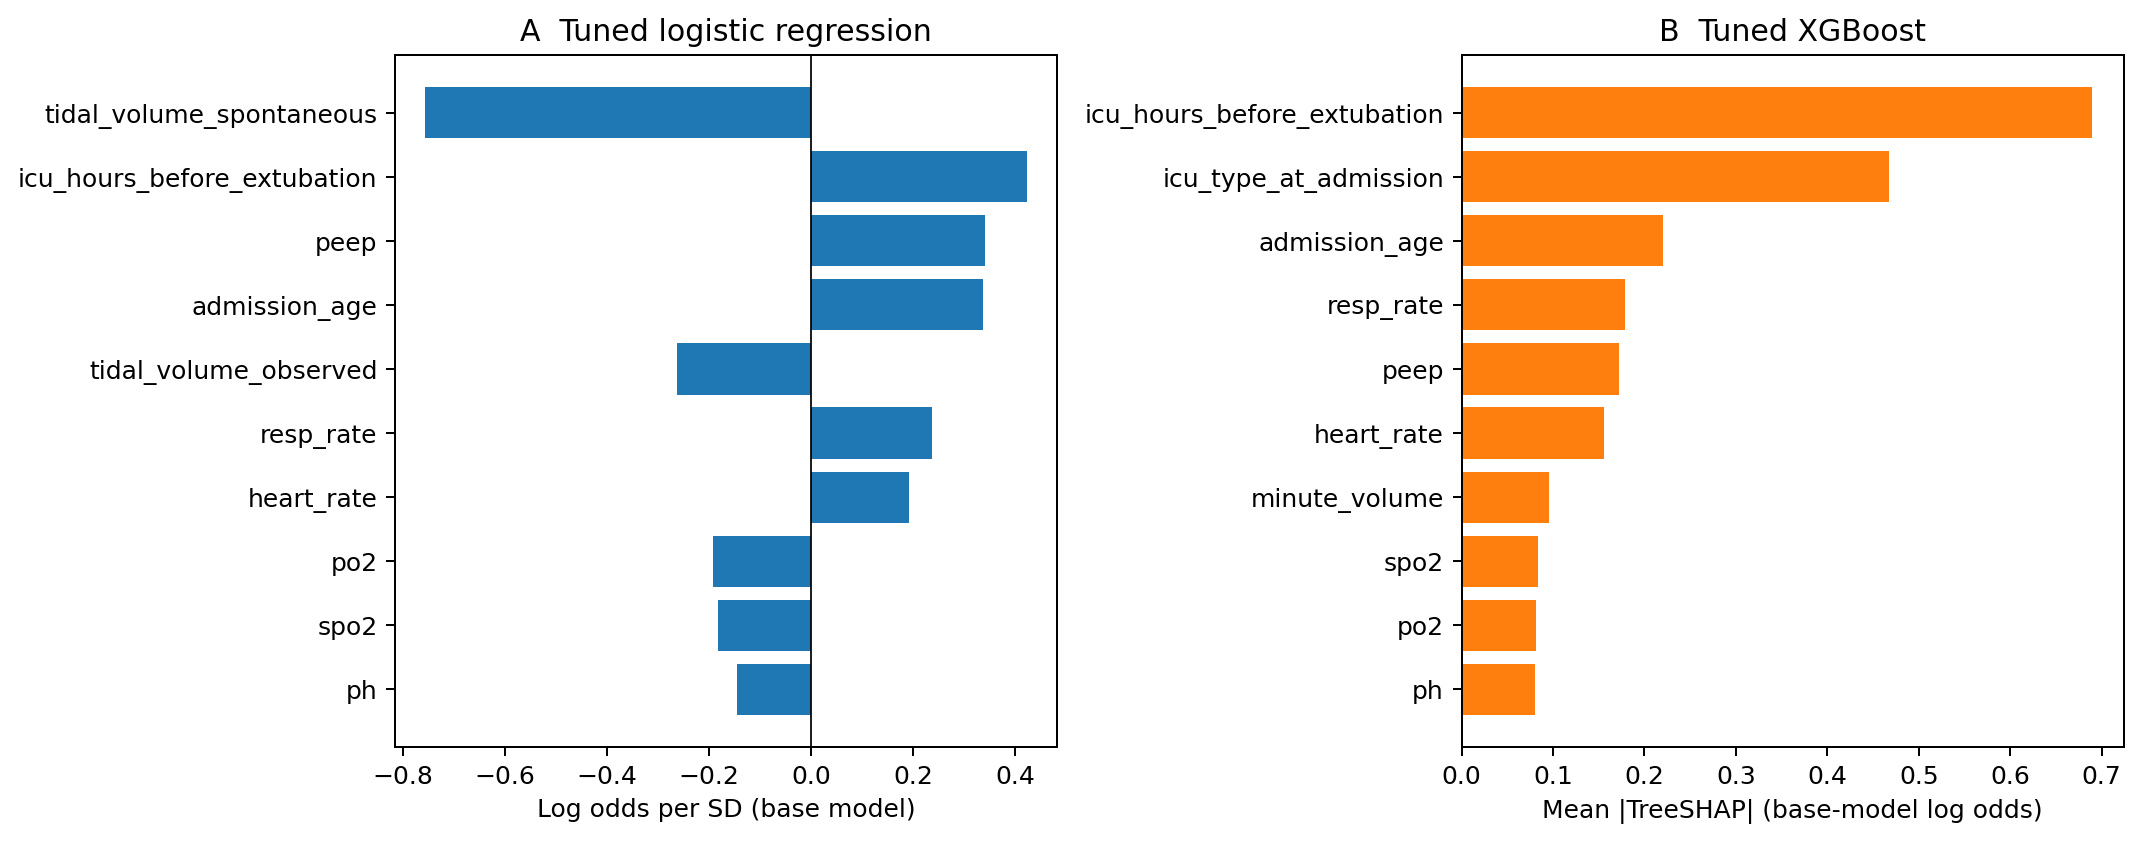

Most-missing predictors (development patients): read coefficients for these with caution


,missing_fraction_development
bicarbonate_mean_6h,0.999
pao2fio2ratio_mean_6h,0.893
fio2_mean_6h,0.892
lactate_mean_6h,0.645
po2_mean_6h,0.369
pco2_mean_6h,0.369
ph_mean_6h,0.367
RSBI_mean_6h,0.216


In [68]:
# Interpretation uses the primary cohort's development patients only.
lr_coefficients, xgb_importance = export_interpretation(runs["filtered_six_hour"])
display(lr_coefficients.head(10).round(3))
display(xgb_importance.head(10).round(4))
display(Image(filename=str(primary_dir / "interpretation_lr_shap.png")))
print("Most-missing predictors (development patients): read coefficients for these with caution")
display(runs["filtered_six_hour"]["missingness"].head(8).to_frame().round(3))

# 4. Test results (Results 3.1–3.3, Table 1, Figures 2–3)

Fixed models evaluated on the temporal test cohort: performance, calibration, decision curves and paired comparisons. Separate death and reintubation analyses are exploratory.


In [69]:
def final_evaluation(run):
    """Score fitted models and keep the results in memory as well as exporting them."""
    bundle, df, out = run["bundle"], run["data"], run["output_dir"]
    frozen = bundle["frozen"]
    cfg = frozen["config"]
    test = df.set_index("subject_id", drop=False).loc[bundle["test_ids"]].reset_index(drop=True)
    warn_small_holdout(frozen["holdout"], cfg)
    X = test[frozen["selected_features"]]
    scores = {n: m.predict_proba(X)[:, 1] for n, m in bundle["models"].items()}
    scores["random_guess"] = np.random.default_rng(cfg["seed"] + 300).uniform(size=len(test))
    predictions = prediction_table(test, cfg, scores, frozen["rsbi_column"])
    table = comparison_tables(predictions, frozen["thresholds"])
    intervals, differences = bootstrap_intervals(predictions, frozen["thresholds"], cfg)
    predictions.to_csv(out / "FINAL_test_predictions.csv", index=False)
    table.to_csv(out / "FINAL_test_metrics.csv", index=False)
    intervals.to_csv(out / "FINAL_test_patient_bootstrap_CI.csv", index=False)
    components = pd.DataFrame()
    if cfg["analysis"] == "filtered_six_hour":
        differences.to_csv(out / "FINAL_paired_model_differences_CI.csv", index=False)
        components = outcome_component_auroc(predictions)
        components.to_csv(out / "FINAL_outcome_component_auroc.csv", index=False)
    return {"predictions": predictions, "metrics": table, "intervals": intervals,
        "paired_differences": differences, "components": components}


def evaluate_suite(runs, configs):
    """Check that both analyses are fitted before scoring either test cohort."""
    if set(runs) != set(configs):
        raise ValueError("Fit both cohorts before test evaluation.")
    for name, cfg in configs.items():
        run = runs[name]
        if cfg != run["bundle"]["frozen"]["config"] or not prepare_cohort(cfg)[0].equals(run["data"]):
            raise ValueError("Data or settings changed after training. Rerun modelling before test evaluation.")
    rows = []
    for name, run in runs.items():
        print("Test evaluation:", name)
        result = final_evaluation(run)
        run["test_results"] = result
        table = result["metrics"]
        table = table[table.scope.eq("all_patients") & table.model.isin(SCORE_MODELS)].drop(columns="scope")
        ci = result["intervals"]
        ci = ci[ci.scope.eq("all_patients") & ci.metric.isin(["auroc", "average_precision"])]
        wide = ci.pivot(index="model", columns="metric", values=["lower_95", "upper_95"])
        wide.columns = [f"{metric}_{bound}" for bound, metric in wide.columns]
        rows.append(table.merge(wide, left_on="model", right_index=True, how="left").assign(
            analysis=name, analysis_note=configs[name]["analysis_note"]))
    result = pd.concat(rows, ignore_index=True)
    result.to_csv(SUITE_DIR / "FINAL_analysis_comparison.csv", index=False)
    return result


def test_sensitivity_analyses(runs):
    """Missingness-filter sensitivity analysis on the test set; each row is a paired difference A − B."""
    primary = runs["filtered_six_hour"]
    cfg = primary["bundle"]["frozen"]["config"]
    reps, seed = cfg["bootstrap_replicates"], cfg["seed"] + 400
    main = primary["test_results"]["predictions"].set_index("subject_id")
    full = runs["full_six_hour"]["test_results"]["predictions"].set_index("subject_id")
    removed = full.index.difference(main.index)  # test patients excluded by the missingness filter
    removed_X = runs["full_six_hour"]["data"].set_index("subject_id").loc[removed, primary["bundle"]["frozen"]["selected_features"]]
    comparisons = []
    for name in MODEL_NAMES:
        comparisons.append(("A full-cohort vs B filtered-cohort training (filtered-cohort patients)",
            name, main.y_true, full.loc[main.index, name], main[name]))
        if len(removed):
            filtered_scores = primary["bundle"]["models"][name].predict_proba(removed_X)[:, 1]
            comparisons.append(("A full-cohort vs B filtered-cohort training (patients removed by filter)",
                name, full.loc[removed, "y_true"], full.loc[removed, name], filtered_scores))
    rows = []
    for i, (label, name, y, a, b) in enumerate(comparisons):
        for r in paired_bootstrap(y, a, b, reps, seed + i):
            rows.append({"comparison": label, "model": name, "patients": len(y), "events": int(np.sum(y)), **r})
    table = pd.DataFrame(rows).rename(columns={"a": "A", "b": "B", "a_minus_b": "A_minus_B"})
    table.to_csv(SUITE_DIR / "FINAL_sensitivity_analyses.csv", index=False)
    return table

Test evaluation: filtered_six_hour


C:\Users\22110\AppData\Local\Temp\ipykernel_47876\2084602672.py:30: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,
C:\Users\22110\AppData\Local\Temp\ipykernel_47876\2084602672.py:30: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,


Test evaluation: full_six_hour
Table A.4: cohort characteristics


,Characteristic,Development,Temporal test,Removed by missingness filter (all years),Full eligible cohort (all years)
0,"Patients, n",15241,880,1761,18620
1,"Age, median [IQR]",66 [55–76],65 [54–74],64 [50–77],66 [55–76]
2,"Female, n (%)",5777 (37.9%),315 (35.8%),769 (43.7%),7170 (38.5%)
3,"ICU hours before extubation, median [IQR]",21.8 [10.5–63.7],40.1 [15.5–96.7],31.4 [14.2–85.2],23.4 [11.0–68.2]
4,"Hospital hours before extubation, median [IQR]",48.5 [22.1–123.2],68.7 [33.6–158.6],43.2 [17.7–133.3],49.6 [22.3–128.6]
5,ICU type: Cardiac Vascular Intensive Care Unit...,6135 (40.3%),326 (37.0%),68 (3.9%),6734 (36.2%)
6,"ICU type: Medical Intensive Care Unit (MICU), ...",2318 (15.2%),121 (13.8%),482 (27.4%),3075 (16.5%)
7,"ICU type: Surgical Intensive Care Unit (SICU),...",2168 (14.2%),74 (8.4%),308 (17.5%),2645 (14.2%)
8,"ICU type: Trauma SICU (TSICU), n (%)",1982 (13.0%),110 (12.5%),311 (17.7%),2467 (13.2%)
9,ICU type: Medical/Surgical Intensive Care Unit...,1368 (9.0%),59 (6.7%),250 (14.2%),1767 (9.5%)


Temporal test metrics (Table 1 uses primary tuned models and random guessing; other rows are exploratory)


,analysis,model,n,events,prevalence,auroc,auroc_lower_95,auroc_upper_95,average_precision,average_precision_lower_95,average_precision_upper_95,brier,scaled_brier,calibration_slope,observed_expected_ratio,threshold,sensitivity,specificity,ppv,npv
0,filtered_six_hour,logistic_regression,880,96,0.109,0.822,0.778,0.864,0.422,0.326,0.544,0.078,0.197,0.974,0.905,0.076,0.906,0.571,0.206,0.980
1,filtered_six_hour,logistic_regression_untuned,880,96,0.109,0.820,0.777,0.863,0.417,0.323,0.537,0.079,0.192,0.961,0.887,0.076,0.896,0.575,0.205,0.978
2,filtered_six_hour,xgboost,880,96,0.109,0.821,0.776,0.862,0.452,0.355,0.565,0.078,0.194,1.157,0.893,0.075,0.875,0.540,0.189,0.972
3,filtered_six_hour,xgboost_untuned,880,96,0.109,0.828,0.784,0.869,0.451,0.355,0.568,0.078,0.197,1.181,0.870,0.072,0.885,0.523,0.185,0.974
4,filtered_six_hour,random_guess,880,96,0.109,0.501,0.442,0.562,0.119,0.090,0.167,NaN,NaN,NaN,NaN,0.500,0.521,0.482,0.110,0.892
5,full_six_hour,logistic_regression,1064,146,0.137,0.816,0.776,0.852,0.426,0.343,0.519,0.098,0.174,0.799,0.878,0.096,0.877,0.583,0.250,0.967
6,full_six_hour,logistic_regression_untuned,1064,146,0.137,0.813,0.772,0.848,0.421,0.340,0.515,0.098,0.171,0.809,0.876,0.096,0.877,0.580,0.249,0.967
7,full_six_hour,xgboost,1064,146,0.137,0.825,0.785,0.859,0.474,0.393,0.563,0.095,0.194,0.956,0.832,0.094,0.877,0.563,0.242,0.966
8,full_six_hour,xgboost_untuned,1064,146,0.137,0.819,0.780,0.853,0.464,0.385,0.553,0.097,0.180,0.929,0.815,0.095,0.877,0.562,0.242,0.966
9,full_six_hour,random_guess,1064,146,0.137,0.501,0.450,0.552,0.142,0.117,0.182,NaN,NaN,NaN,NaN,0.500,0.527,0.490,0.141,0.867


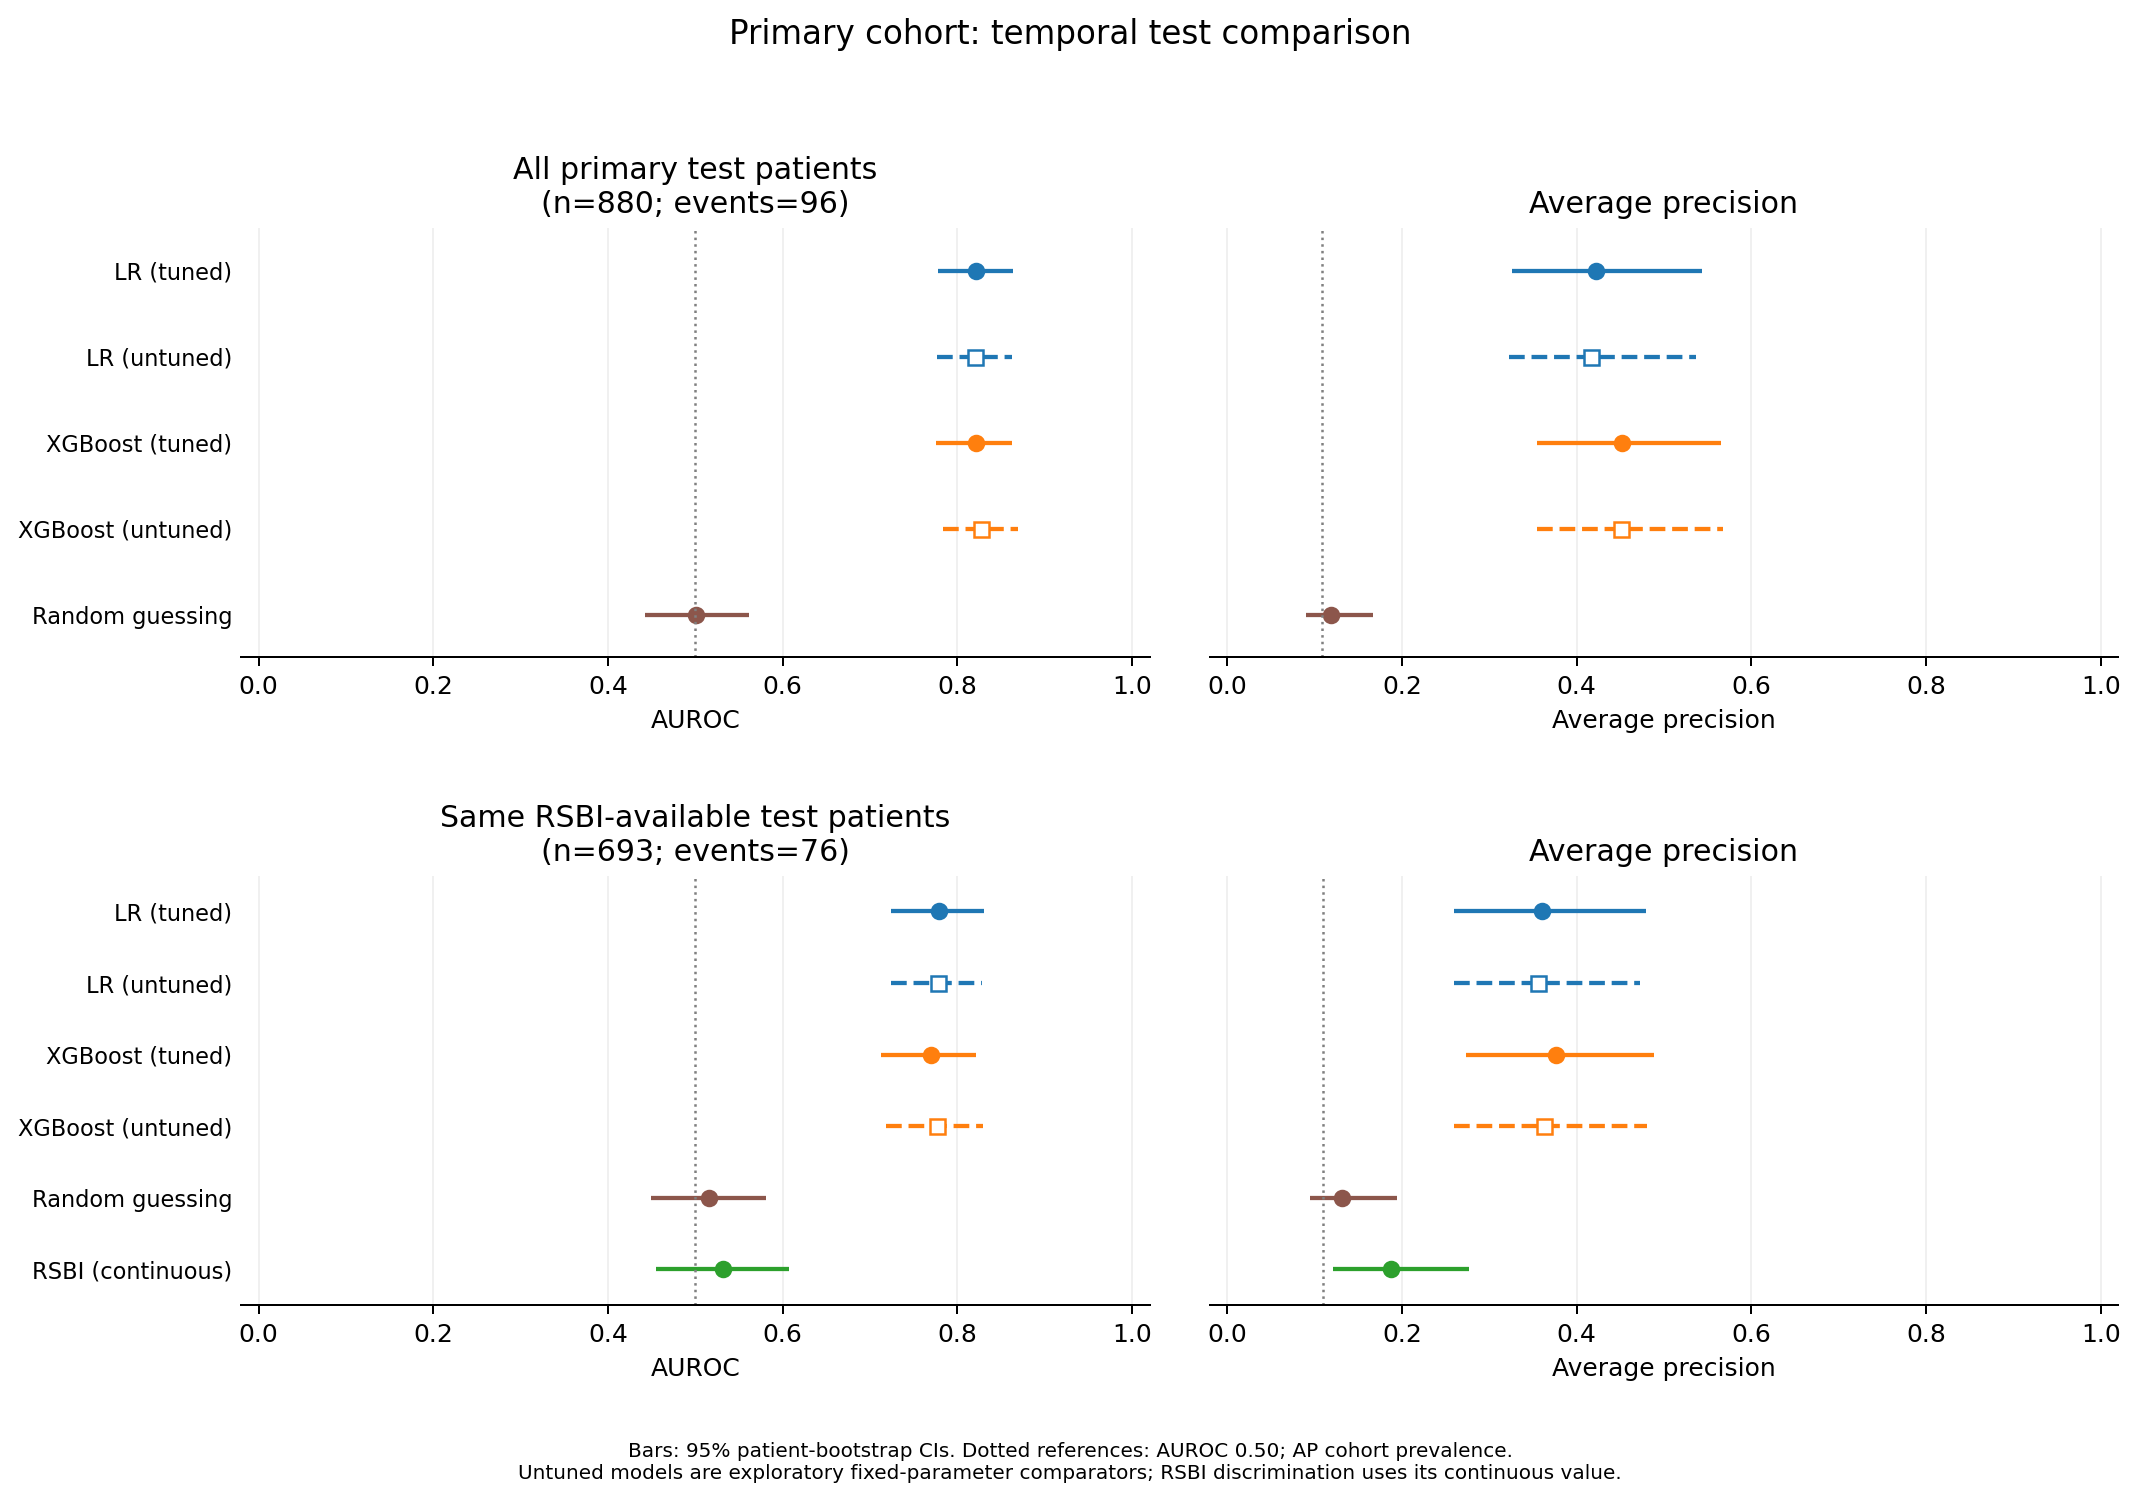

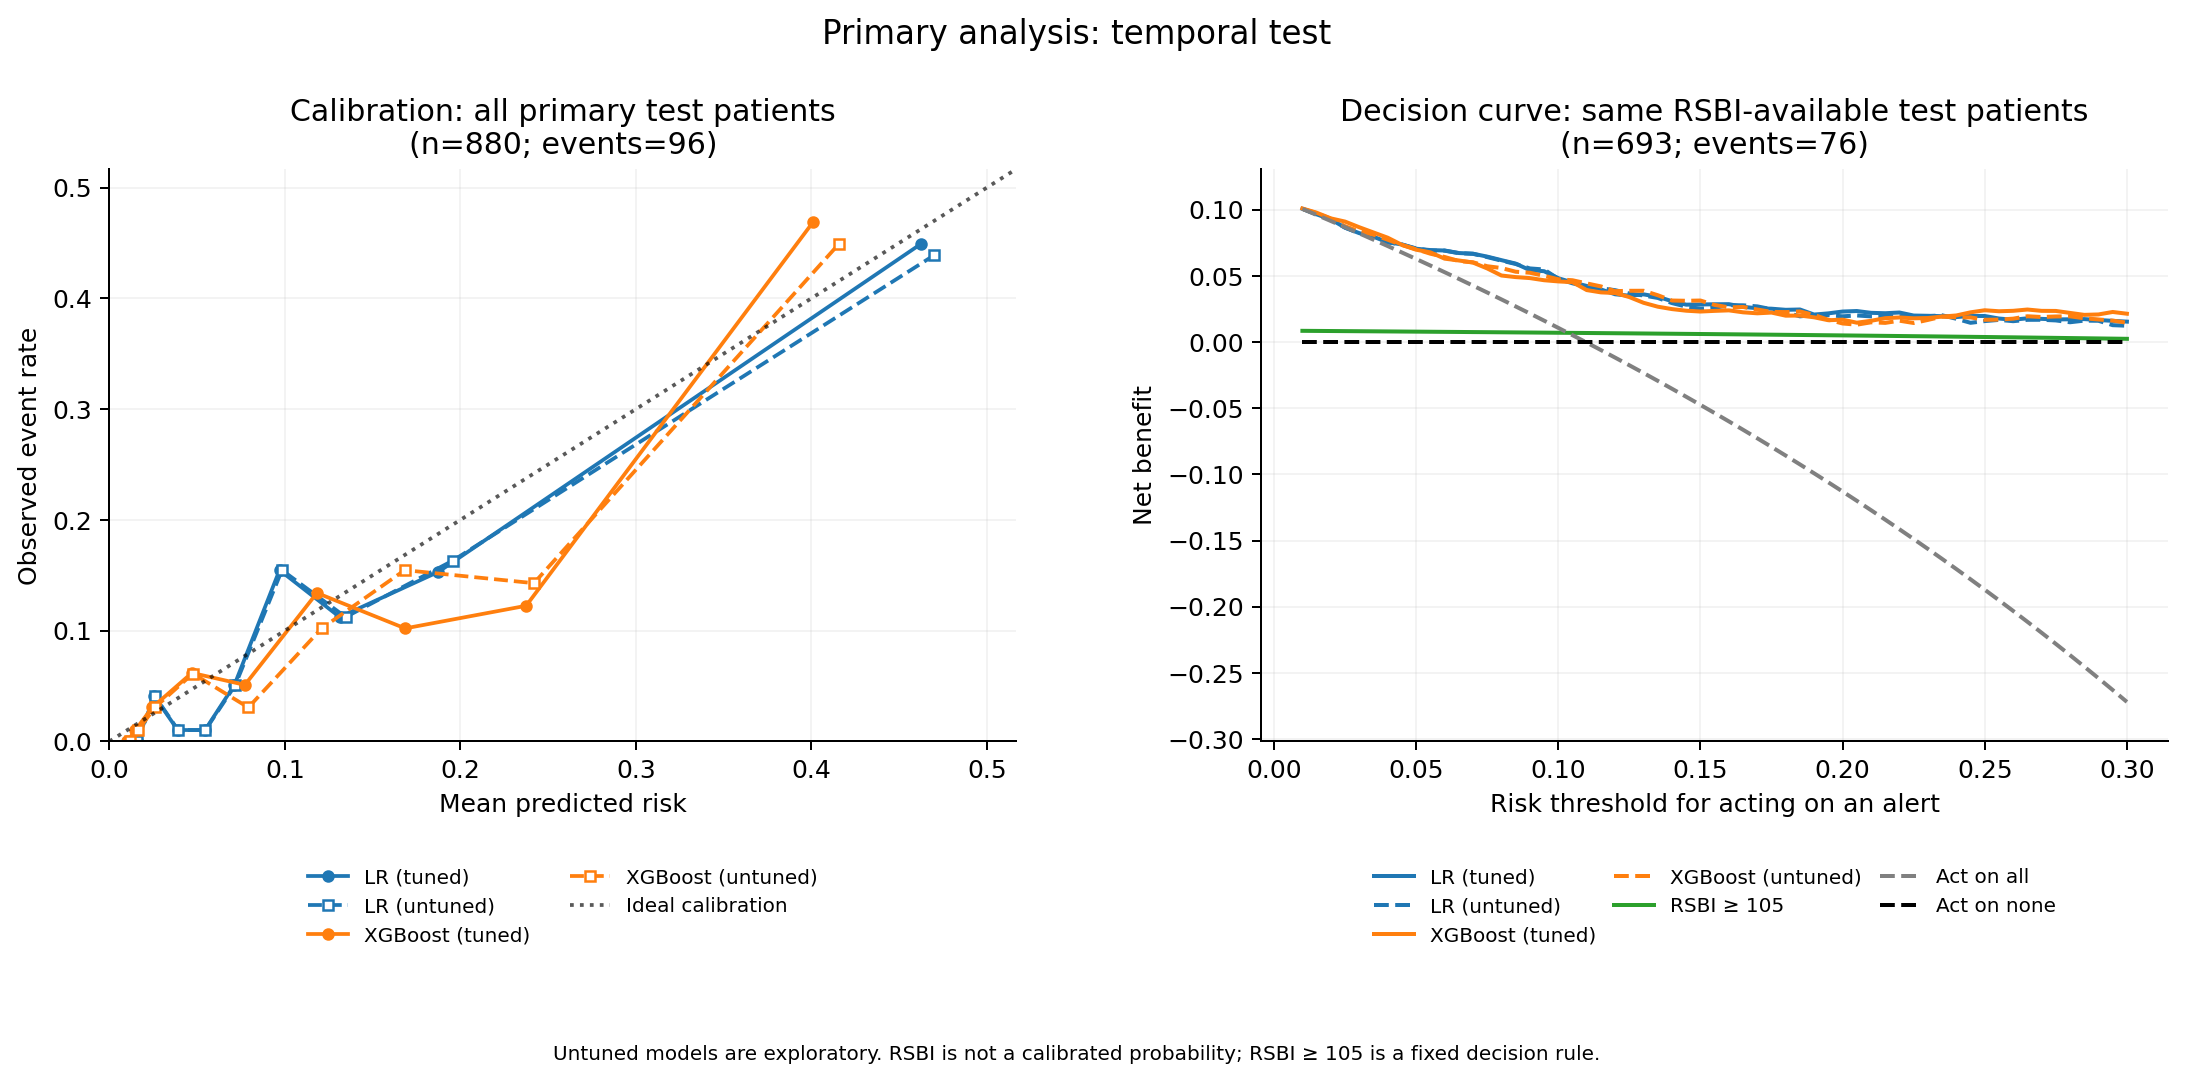

Net benefit at selected risk thresholds (decision-curve patients)


strategy,logistic_regression,logistic_regression_untuned,rsbi_ge_105,treat_all,treat_none,xgboost,xgboost_untuned
threshold,,,,,,,
0.05,0.0706,0.0708,0.0079,0.0628,0.0,0.0698,0.0702
0.10,0.0483,0.0478,0.0071,0.0107,0.0,0.0459,0.0475
0.15,0.0284,0.0252,0.0061,-0.0474,0.0,0.0231,0.0314
0.20,0.0231,0.0195,0.0051,-0.1129,0.0,0.0170,0.0141
0.25,0.0197,0.0159,0.0038,-0.1871,0.0,0.0241,0.0168
0.30,0.0155,0.0124,0.0025,-0.2719,0.0,0.0214,0.0146


Paired model differences A − B: XGBoost vs LR and tuned vs untuned (exploratory additions)


,model_a,model_b,metric,valid_replicates,lower_95,upper_95,n,events,a,b,a_minus_b
0,logistic_regression,logistic_regression_untuned,auroc,1000,-0.001,0.004,880,96,0.822,0.820,0.001
1,logistic_regression,logistic_regression_untuned,average_precision,1000,-0.001,0.013,880,96,0.422,0.417,0.006
2,logistic_regression,logistic_regression_untuned,brier,1000,-0.001,-0.000,880,96,0.078,0.079,-0.001
3,xgboost,logistic_regression,auroc,1000,-0.024,0.023,880,96,0.821,0.822,-0.000
4,xgboost,logistic_regression,average_precision,1000,-0.028,0.083,880,96,0.452,0.422,0.029
5,xgboost,logistic_regression,brier,1000,-0.004,0.005,880,96,0.078,0.078,0.000
6,xgboost,xgboost_untuned,auroc,1000,-0.016,0.003,880,96,0.821,0.828,-0.006
7,xgboost,xgboost_untuned,average_precision,1000,-0.023,0.022,880,96,0.452,0.451,0.001
8,xgboost,xgboost_untuned,brier,1000,-0.001,0.002,880,96,0.078,0.078,0.000


All comparators on identical RSBI-available test patients; continuous RSBI for AUROC/AP, threshold 105 for classification


,model,n,events,auroc,average_precision,sensitivity,specificity,ppv,npv,auroc_lower_95,auroc_upper_95,average_precision_lower_95,average_precision_upper_95
0,logistic_regression,693,76,0.779,0.361,0.895,0.517,0.186,0.976,0.724,0.830,0.260,0.479
1,logistic_regression_untuned,693,76,0.778,0.356,0.882,0.522,0.185,0.973,0.724,0.828,0.259,0.473
2,xgboost,693,76,0.770,0.377,0.855,0.472,0.166,0.964,0.712,0.822,0.273,0.489
3,xgboost_untuned,693,76,0.777,0.363,0.868,0.464,0.166,0.966,0.718,0.829,0.260,0.480
4,random_guess,693,76,0.516,0.131,0.553,0.476,0.115,0.896,0.449,0.581,0.095,0.194
5,rsbi,693,76,0.532,0.188,0.079,0.984,0.375,0.897,0.455,0.607,0.122,0.276


Results 3.3: exploratory missingness-filter sensitivity, paired differences with 95% CIs


,comparison,model,patients,events,metric,A,B,A_minus_B,lower_95,upper_95,valid_replicates
0,A full-cohort vs B filtered-cohort training (f...,logistic_regression,880,96,auroc,0.826,0.822,0.004,-0.002,0.011,1000
1,A full-cohort vs B filtered-cohort training (f...,logistic_regression,880,96,average_precision,0.439,0.422,0.016,0.004,0.029,1000
2,A full-cohort vs B filtered-cohort training (f...,logistic_regression,880,96,brier,0.077,0.078,-0.001,-0.003,0.001,1000
3,A full-cohort vs B filtered-cohort training (p...,logistic_regression,184,50,auroc,0.709,0.698,0.011,-0.002,0.024,1000
4,A full-cohort vs B filtered-cohort training (p...,logistic_regression,184,50,average_precision,0.433,0.415,0.017,-0.002,0.042,1000
5,A full-cohort vs B filtered-cohort training (p...,logistic_regression,184,50,brier,0.196,0.201,-0.005,-0.012,0.003,1000
6,A full-cohort vs B filtered-cohort training (f...,logistic_regression_untuned,880,96,auroc,0.823,0.820,0.002,-0.005,0.009,1000
7,A full-cohort vs B filtered-cohort training (f...,logistic_regression_untuned,880,96,average_precision,0.433,0.417,0.017,-0.000,0.033,1000
8,A full-cohort vs B filtered-cohort training (f...,logistic_regression_untuned,880,96,brier,0.078,0.079,-0.001,-0.003,0.001,1000
9,A full-cohort vs B filtered-cohort training (p...,logistic_regression_untuned,184,50,auroc,0.710,0.692,0.018,0.001,0.035,1000


Results 3.2: exploratory death and reintubation analysis


,component,model,events,non_events,auroc
0,death_within_48_hours,logistic_regression,50,784,0.871
1,death_within_48_hours,logistic_regression_untuned,50,784,0.868
2,death_within_48_hours,xgboost,50,784,0.896
3,death_within_48_hours,xgboost_untuned,50,784,0.906
4,reintubation_within_48_hours,logistic_regression,49,784,0.759
5,reintubation_within_48_hours,logistic_regression_untuned,49,784,0.759
6,reintubation_within_48_hours,xgboost,49,784,0.736
7,reintubation_within_48_hours,xgboost_untuned,49,784,0.742


In [70]:
final_results = evaluate_suite(runs, RUN_CONFIGS)
TABLE_1 = cohort_table(runs)
TABLE_1.to_csv(SUITE_DIR / "table1_cohort.csv", index=False)
print("Table A.4: cohort characteristics")
display(TABLE_1)

summary_columns = ["analysis", "model", "n", "events", "prevalence", "auroc", "auroc_lower_95", "auroc_upper_95",
    "average_precision", "average_precision_lower_95", "average_precision_upper_95", "brier", "scaled_brier",
    "calibration_slope", "observed_expected_ratio", "threshold", "sensitivity", "specificity", "ppv", "npv"]
print("Temporal test metrics (Table 1 uses primary tuned models and random guessing; other rows are exploratory)")
display(final_results[summary_columns].round(3))
primary_results = runs["filtered_six_hour"]["test_results"]
test_rsbi = rsbi_comparison(primary_results["metrics"], primary_results["intervals"])
test_rsbi.to_csv(SUITE_DIR / "FINAL_rsbi_comparison.csv", index=False)
plot_model_comparison(final_results[final_results.analysis.eq("filtered_six_hour")], test_rsbi,
    SUITE_DIR / "FINAL_model_comparison.png", "Primary cohort: temporal test comparison")
display(Image(filename=str(SUITE_DIR / "FINAL_model_comparison.png")))
primary_test = primary_results["predictions"]
calibration_figure, decision_curve_table = plot_calibration_and_utility(
    primary_test, CONFIG["decision_curve_max_threshold"], SUITE_DIR, "Primary analysis: temporal test")
display(Image(filename=str(calibration_figure)))
net_benefit_table = decision_curve_table.pivot(
    index="threshold", columns="strategy", values="net_benefit")
print("Net benefit at selected risk thresholds (decision-curve patients)")
display(net_benefit_table.loc[net_benefit_table.index.isin([0.05, 0.1, 0.15, 0.2, 0.25, 0.3])].round(4))

print("Paired model differences A − B: XGBoost vs LR and tuned vs untuned (exploratory additions)")
display(primary_results["paired_differences"].round(3))
print("All comparators on identical RSBI-available test patients; continuous RSBI for AUROC/AP, threshold 105 for classification")
display(test_rsbi.round(3))

print("Results 3.3: exploratory missingness-filter sensitivity, paired differences with 95% CIs")
sensitivity = test_sensitivity_analyses(runs)
display(sensitivity.round(3))
print("Results 3.2: exploratory death and reintubation analysis")
components = primary_results["components"]
display(components[components.model.isin(MODEL_NAMES)].reset_index(drop=True).round(3))

### Exploratory missingness-filter sensitivity (Results 3.3)

Full-trained and filtered-trained models compared on the same test patients within each missingness group, with paired bootstrap intervals.


Patients/events per comparison: {'(filtered-cohort test patients)': '880/96', '(test patients removed by filter)': '184/50'}


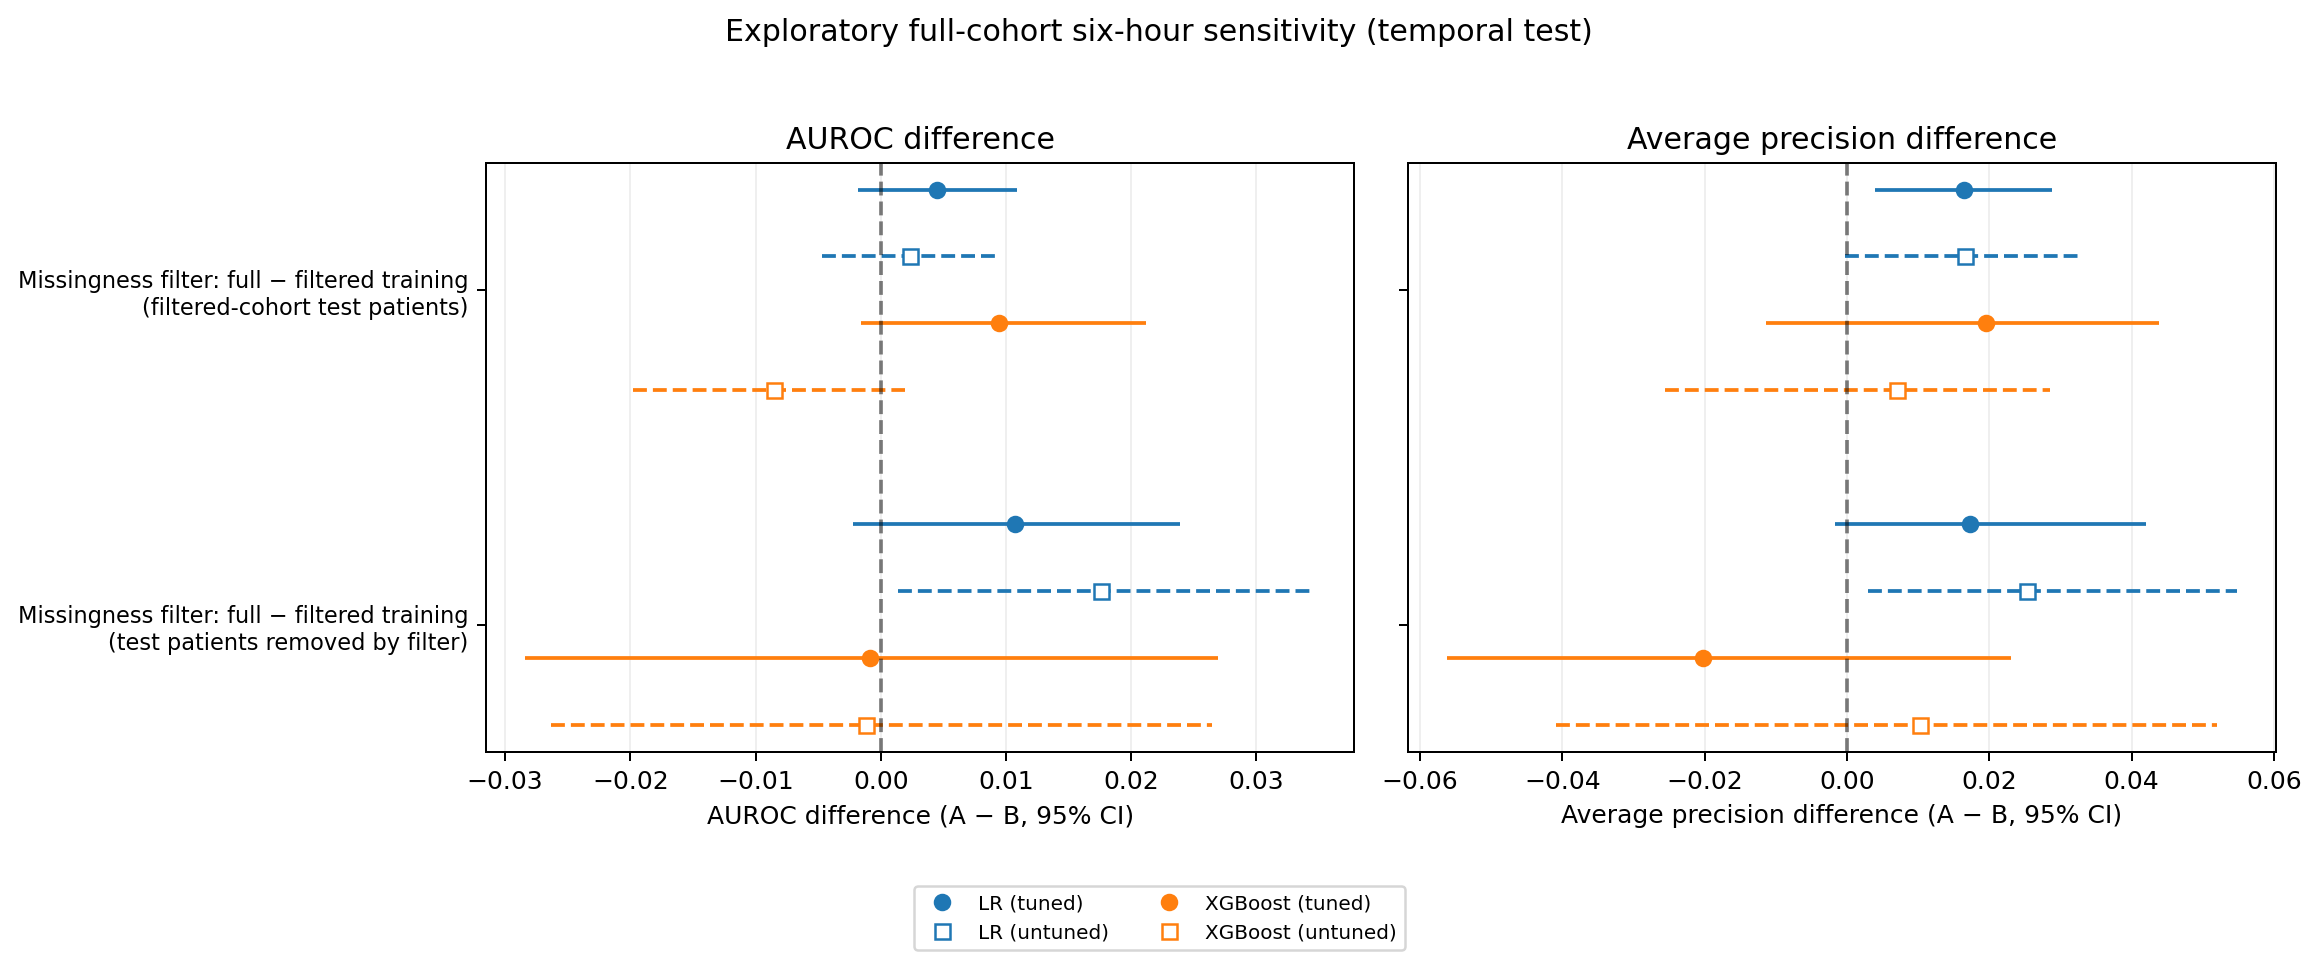

In [71]:
# Missingness-filter sensitivity analysis on the temporal test set: paired differences A − B with 95% bootstrap CIs.
row_labels = {
    "A full-cohort vs B filtered-cohort training (filtered-cohort patients)":
        "Missingness filter: full − filtered training\n(filtered-cohort test patients)",
    "A full-cohort vs B filtered-cohort training (patients removed by filter)":
        "Missingness filter: full − filtered training\n(test patients removed by filter)",
}
comparisons = [c for c in row_labels if c in set(sensitivity.comparison)]
fig, axes = plt.subplots(1, 2, figsize=(13, 1.6 * len(comparisons) + 2.1), sharey=True)
for ax, metric, title in zip(axes, ["auroc", "average_precision"], ["AUROC difference", "Average precision difference"]):
    for model, offset in zip(MODEL_NAMES, np.linspace(-0.30, 0.30, len(MODEL_NAMES))):
        rows = sensitivity[sensitivity.metric.eq(metric) & sensitivity.model.eq(model)].set_index("comparison").loc[comparisons]
        y = np.arange(len(comparisons)) + offset
        ax.hlines(y, rows.lower_95, rows.upper_95, color=COLOURS[model], linestyles=LINESTYLES[model])
        ax.plot(rows.A_minus_B, y, MARKERS[model], color=COLOURS[model], markerfacecolor="white" if model.endswith("_untuned") else COLOURS[model], label=LABELS[model])
    ax.axvline(0, color="k", linestyle="--", alpha=.5)  # 0 = no difference
    ax.set(xlabel=f"{title} (A − B, 95% CI)", title=title)
    ax.grid(axis="x", alpha=.2)
axes[0].set_yticks(range(len(comparisons)), [row_labels[c] for c in comparisons], fontsize=9)
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=8, loc="lower center", ncol=2)
patients = sensitivity.drop_duplicates("comparison").set_index("comparison").loc[comparisons]
print("Patients/events per comparison:", dict(zip([row_labels[c].split("\n")[1] for c in comparisons],
    [f"{int(n)}/{int(e)}" for n, e in zip(patients.patients, patients.events)])))
fig.suptitle("Exploratory full-cohort six-hour sensitivity (temporal test)")
fig.tight_layout(rect=(0, .10, 1, .96))
fig.savefig(SUITE_DIR / "FINAL_sensitivity_analyses.png", dpi=180, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(SUITE_DIR / "FINAL_sensitivity_analyses.png")))

## Generative AI declaration

We declare the use of claude [claude.ai] and ChatGPT[openai.com] to check the code, formate and structure it. We also used them to check for grammar, sentence structure and overall flow of the code and the report. 